# Tournées de coursiers avec fenêtres horaires, augmentées par le Machine Learning

**Projet Machine Learning & Optimisation logistique — dataset LaDe-P (Cainiao), ville de Yantai**

Professeur : Mr Slim Ayedi

---

## A. Introduction

### Le contexte métier
Dans la logistique du *dernier kilomètre*, un coursier part le matin et doit **collecter des colis** chez des clients (commerçants, particuliers). Chaque colis a une **fenêtre horaire promise** au client (par exemple 9 h – 11 h). Les demandes arrivent **au fil de la journée** : le coursier ne connaît pas toutes ses tâches au départ.

### Le problème logistique
À chaque fois qu'il termine une collecte, le coursier doit décider : **« Où vais-je maintenant ? »**
Un mauvais ordre de visite = des kilomètres inutiles, du temps perdu et des fenêtres horaires dépassées.

### La décision à optimiser
**L'ordre de visite des points de collecte**, décidé à chaque arrêt, parmi les tâches déjà connues.
C'est une variante dynamique du **problème du voyageur de commerce avec fenêtres horaires (TSPTW)**, un problème classique d'optimisation combinatoire (NP-difficile).

### L'intérêt du Machine Learning
Un algorithme d'optimisation a besoin de connaître **le temps nécessaire pour aller d'un point à un autre**. Ce temps n'est pas dans les données : il dépend de la distance, du type de lieu, de l'heure de la journée, du quartier… Le ML **apprend ce temps** à partir de près d'un million de trajets réels, puis fournit à l'optimiseur une **matrice de temps** plus réaliste qu'une simple formule « distance ÷ vitesse moyenne ».

> **En une phrase :** le ML *prédit* les temps de trajet ; l'optimisation *décide* l'ordre de visite à partir de ces prédictions.

### Les KPI suivis
| KPI | Signification | Unité |
|---|---|---|
| Distance parcourue | somme des distances entre visites successives (calcul exact, sans modèle) | km |
| Temps de déplacement | somme des temps de trajet + service | min |
| Durée de la tournée | de la première à la dernière collecte (inclut l'attente de nouvelles tâches) | min |
| Collectes en retard | nombre de visites après la fin de leur fenêtre | nombre |
| Minutes de retard | retard cumulé | min |

### Les trois stratégies comparées
1. **Référence terrain** : l'ordre *réellement* suivi par le coursier (enregistré dans les données).
2. **Scénario 1 — Sans ML** : le même optimiseur, mais avec une formule traditionnelle « temps de service moyen + distance ÷ vitesse moyenne ».
3. **Scénario 2 — Avec ML** : le même optimiseur, avec la matrice de temps prédite par le modèle ML.

Comparer 2 et 3 isole la **valeur ajoutée du ML** ; comparer 1 et 2/3 mesure la **valeur ajoutée de l'optimisation**.

## B. Importation et exploration du dataset

### B.1 Bibliothèques et paramètres
Toutes les bibliothèques sont gratuites et déjà installées dans Google Colab : `pandas`, `numpy`, `matplotlib`, `scikit-learn` et `scipy` (pour le solveur MILP exact **HiGHS**). Aucune installation supplémentaire n'est nécessaire.

In [ ]:
# B.1 — Importations et paramètres globaux

import json, time, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.stats import wilcoxon

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 42                      # graine aléatoire : résultats reproductibles
rng = np.random.default_rng(SEED)

#  Dossiers du projet (fonctionne en local depuis notebook/ ou dans Colab) ---
BASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_PATH = BASE / "data" / "pickup_yt.csv"
FIG_DIR = BASE / "rapport" / "figures"
EXP_DIR = BASE / "exports"
WEB_DIR = BASE / "web" / "data"
for d in (FIG_DIR, EXP_DIR, WEB_DIR):
    d.mkdir(parents=True, exist_ok=True)

#  Style graphique commun (palette validée, lisible en impression) ---
C_REEL, C_SANS, C_AVEC, C_GRIS = "#8a8985", "#eb6834", "#2a78d6", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.edgecolor": "#888", "legend.frameon": False,
})

def sauver(fig, nom):
    """Enregistre une figure en PNG haute qualité pour le rapport."""
    fig.savefig(FIG_DIR / f"{nom}.png", bbox_inches="tight", facecolor="white")

print("Dossier du projet :", BASE)
print("Fichier de données :", DATA_PATH, "| trouvé :", DATA_PATH.exists())

Dossier du projet : /home/claude/proj/Projet_Tournees_LaDe
Fichier de données : /home/claude/proj/Projet_Tournees_LaDe/data/pickup_yt.csv | trouvé : True


### B.2 Chargement du fichier
Le fichier `pickup_yt.csv` provient du dataset public **LaDe** (Cainiao, licence Apache-2.0), sous-ensemble *pickup* (collecte), ville de **Yantai**.
Téléchargement : https://huggingface.co/datasets/Cainiao-AI/LaDe/tree/main (dossier `pickup`).

> Dans Google Colab : déposez le fichier dans un dossier `data/` (ou modifiez `DATA_PATH`).

In [ ]:
# B.2 — Chargement

raw = pd.read_csv(DATA_PATH)
print(f"Dimensions : {raw.shape[0]:,} lignes × {raw.shape[1]} colonnes".replace(",", " "))
display(raw.head(5))

Dimensions : 1 146 781 lignes × 19 colonnes


,order_id,region_id,city,courier_id,accept_time,time_window_start,time_window_end,lng,lat,aoi_id,aoi_type,pickup_time,pickup_gps_time,pickup_gps_lng,pickup_gps_lat,accept_gps_time,accept_gps_lng,accept_gps_lat,ds
0,4732519,16,Yantai,992,05-18 08:16:00,05-18 09:00:00,05-18 11:00:00,121.21661,36.77277,32,1,05-18 08:42:00,05-18 08:42:00,121.22029,36.77386,05-18 08:10:00,121.21800,36.77443,518
1,5411237,16,Yantai,992,05-14 09:17:00,05-14 13:00:00,05-14 15:00:00,121.21923,36.77317,32,1,05-14 12:40:00,05-14 12:40:00,121.22033,36.77403,05-14 09:16:00,121.21094,36.78368,514
2,143142,16,Yantai,992,05-10 15:30:00,05-10 15:30:00,05-10 17:30:00,121.22025,36.77384,32,1,05-10 15:54:00,05-10 15:54:00,121.22032,36.77409,05-10 15:29:00,121.22023,36.77399,510
3,3421498,16,Yantai,992,05-05 12:47:00,05-05 12:47:00,05-05 14:47:00,121.21676,36.77269,32,1,05-05 13:50:00,05-05 13:50:00,121.22058,36.77391,NaN,NaN,NaN,505
4,362894,16,Yantai,992,05-11 08:02:00,05-11 09:00:00,05-11 11:00:00,121.22031,36.77385,32,1,05-11 09:04:00,05-11 09:03:00,121.22030,36.77395,05-11 07:58:00,121.21808,36.77453,511


### B.3 Description des variables
Chaque ligne = **un colis à collecter**. Voici à quoi sert chaque variable dans notre problème :

| Variable | Description | Rôle dans le projet |
|---|---|---|
| `order_id` | identifiant du colis | clé |
| `courier_id` | identifiant du coursier | regroupe les colis en tournées |
| `ds` | date (format MMJJ) | regroupe en journées ; découpage temporel |
| `lng`, `lat` | coordonnées du point de collecte | calcul des distances |
| `region_id`, `aoi_id`, `aoi_type` | zone, « aire d'intérêt » et son type (bureau, résidence…) | variables explicatives du ML |
| `time_window_start`, `time_window_end` | fenêtre horaire promise au client | contrainte d'échéance de l'optimisation |
| `accept_time` | moment où la tâche est connue du coursier | dynamique : on ne peut pas planifier une tâche avant qu'elle existe |
| `pickup_time` | moment réel de la collecte | séquence réelle ; cible du ML |
| `*_gps_*` | position GPS du coursier à l'acceptation / à la collecte | contrôle qualité seulement (souvent manquant) |

In [ ]:
# B.3 — Types, statistiques descriptives, valeurs manquantes
print("Types des colonnes :")
print(raw.dtypes.to_string())

print("\nStatistiques descriptives des variables numériques :")
display(raw[["lng", "lat", "region_id", "aoi_id", "aoi_type"]].describe().round(4))

manq = raw.isna().sum()
manq = pd.DataFrame({"manquantes": manq, "pourcentage": (100 * manq / len(raw)).round(1)})
print("\nValeurs manquantes par colonne :")
display(manq[manq.manquantes > 0])

print("Nombre de coursiers :", raw.courier_id.nunique())
print("Nombre de régions   :", raw.region_id.nunique(), "| nombre d'AOI :", raw.aoi_id.nunique())
print("Nombre de journées  :", raw.ds.nunique(), f"(du {raw.ds.min()} au {raw.ds.max()}, format MMJJ)")

Types des colonnes :
order_id               int64
region_id              int64
city                     str
courier_id             int64
accept_time              str
time_window_start        str
time_window_end          str
lng                  float64
lat                  float64
aoi_id                 int64
aoi_type               int64
pickup_time              str
pickup_gps_time          str
pickup_gps_lng       float64
pickup_gps_lat       float64
accept_gps_time          str
accept_gps_lng       float64
accept_gps_lat       float64
ds                     int64

Statistiques descriptives des variables numériques :

Valeurs manquantes par colonne :
Nombre de coursiers : 2593
Nombre de régions   : 30 | nombre d'AOI : 6024
Nombre de journées  : 184 (du 501 au 1031, format MMJJ)


,lng,lat,region_id,aoi_id,aoi_type
count,1.146781e+06,1.146781e+06,1.146781e+06,1.146781e+06,1.146781e+06
mean,1.210503e+02,3.744530e+01,1.118507e+02,1.219099e+04,6.411200e+00
std,4.666000e-01,2.095000e-01,2.150510e+01,7.036729e+03,6.216000e+00
min,1.198508e+02,3.671590e+01,1.600000e+01,1.000000e+00,0.000000e+00
25%,1.207147e+02,3.741420e+01,1.080000e+02,6.180000e+03,1.000000e+00
50%,1.212568e+02,3.751690e+01,1.160000e+02,1.199300e+04,1.000000e+00
75%,1.213670e+02,3.755730e+01,1.240000e+02,1.819400e+04,1.400000e+01
max,1.216342e+02,3.781650e+01,1.340000e+02,2.454200e+04,1.400000e+01


,manquantes,pourcentage
pickup_gps_time,239712,20.9
pickup_gps_lng,239712,20.9
pickup_gps_lat,239712,20.9
accept_gps_time,412040,35.9
accept_gps_lng,412040,35.9
accept_gps_lat,412040,35.9


### B.4 Problèmes de qualité identifiés
* **Pas d'année dans les dates** (`05-18 08:16:00`) : on ajoute une année fictive (2022) uniquement pour manipuler les dates. **Conséquence :** le *jour de la semaine* est inconnu ; nous ne l'utilisons donc pas comme variable.
* **Colonnes GPS manquantes** (≈ 21 % et 36 %) : nous ne les utilisons pas pour le modèle ; les coordonnées déclarées du point de collecte (`lng`, `lat`) sont complètes.
* **Fenêtres horaires** : à vérifier (longueur, respect réel).
* **Arrivée progressive des tâches** (`accept_time`) : à mesurer, car cela conditionne la façon d'optimiser.

## C. Data Preprocessing

### C.1 Conversion des dates et contrôles de cohérence
*Ce que nous faisons :* convertir les textes en dates, puis vérifier les doublons et les incohérences temporelles.
*Pourquoi :* une collecte avant l'acceptation de la tâche, ou une fenêtre qui finit avant de commencer, serait une erreur de données.

In [ ]:
# C.1 — Dates, doublons, cohérence

df = raw.copy()
TCOLS = ["accept_time", "time_window_start", "time_window_end", "pickup_time"]
for c in TCOLS:
    df[c] = pd.to_datetime("2022-" + df[c].astype(str), format="%Y-%m-%d %H:%M:%S")

journal = []   # journal du preprocessing, réutilisé par le rapport et le site
def noter(etape, lignes, explication):
    journal.append({"etape": etape, "lignes": int(lignes), "explication": explication})
    print(f"[{etape}] {lignes:,} — {explication}".replace(",", " "))

noter("Données brutes", len(df), "colis chargés")
noter("Doublons exacts", df.duplicated().sum(), "lignes identiques")
noter("Identifiants en double", df.order_id.duplicated().sum(), "order_id répétés")
noter("Collecte avant acceptation", (df.pickup_time < df.accept_time).sum(), "incohérence temporelle")
noter("Fenêtre inversée", (df.time_window_end <= df.time_window_start).sum(), "fin avant le début")

duree_fen = (df.time_window_end - df.time_window_start).dt.total_seconds() / 60
print(f"\nLongueur des fenêtres : médiane {duree_fen.median():.0f} min, "
      f"{(duree_fen == 120).mean():.1%} des fenêtres font exactement 2 h")
print(f"Collectes AVANT le début de fenêtre : {(df.pickup_time < df.time_window_start).mean():.1%}")
print(f"Collectes APRÈS la fin de fenêtre   : {(df.pickup_time > df.time_window_end).mean():.2%}")

[Données brutes] 1 146 781 — colis chargés
[Doublons exacts] 0 — lignes identiques
[Identifiants en double] 0 — order_id répétés
[Collecte avant acceptation] 0 — incohérence temporelle
[Fenêtre inversée] 0 — fin avant le début

Longueur des fenêtres : médiane 120 min, 99.3% des fenêtres font exactement 2 h
Collectes AVANT le début de fenêtre : 31.2%
Collectes APRÈS la fin de fenêtre   : 0.47%


**Lecture :** aucun doublon ni incohérence. Deux constats importants :
* Les fenêtres font presque toujours **2 heures**.
* Les coursiers collectent souvent **avant** le début de la fenêtre, et très rarement **après** la fin. Le **début** de fenêtre n'est donc pas une contrainte réelle ; la **fin** de fenêtre est une **échéance** (*deadline*).

**Choix de modélisation :** dans l'optimisation, la fin de fenêtre sera une échéance pénalisée ; on n'imposera pas d'attendre le début de la fenêtre (cela reproduit la pratique observée).

### C.2 Détection des valeurs aberrantes (outliers) géographiques
*Pourquoi :* un point de collecte à 500 km de la ville fausserait les distances.

In [ ]:
# C.2 — Outliers géographiques

q = df[["lng", "lat"]].quantile([0.001, 0.999])
print("Étendue des coordonnées déclarées (0,1 % – 99,9 %) :")
display(q.round(4))
hors_zone = ~df.lng.between(119.5, 122.0) | ~df.lat.between(36.5, 38.0)
noter("Points hors de la zone de Yantai", hors_zone.sum(), "coordonnées aberrantes (aucune suppression nécessaire si 0)")
df = df[~hors_zone].copy()

Étendue des coordonnées déclarées (0,1 % – 99,9 %) :
[Points hors de la zone de Yantai] 0 — coordonnées aberrantes (aucune suppression nécessaire si 0)


,lng,lat
0.001,119.9108,36.7342
0.999,121.6135,37.8143


### C.3 Feature engineering : des colis aux *visites*
*Ce que nous faisons :* nous trions les colis de chaque coursier par heure de collecte. Plusieurs colis consécutifs au **même endroit** sont regroupés en une seule **visite** (le coursier ne se déplace pas entre eux).

Pour chaque visite nous calculons :
* `t_debut` / `t_fin` : première et dernière collecte de la visite ;
* `connue_a` (*release time*) : moment où **tous** ses colis sont connus (max de `accept_time`) — choix prudent ;
* `echeance` : la fin de fenêtre la plus contraignante de ses colis ;
* `n_colis` : nombre de colis collectés.

In [ ]:
# C.3 — Construction des visites

df = df.sort_values(["courier_id", "ds", "pickup_time", "order_id"]).reset_index(drop=True)
df["cle_lieu"] = df.lng.round(4).astype(str) + "_" + df.lat.round(4).astype(str)
nouvelle = df.cle_lieu != df.groupby(["courier_id", "ds"]).cle_lieu.shift()
df["visite"] = nouvelle.astype(int).groupby([df.courier_id, df.ds]).cumsum()

visites = (df.groupby(["courier_id", "ds", "visite"])
             .agg(lng=("lng", "first"), lat=("lat", "first"), region_id=("region_id", "first"),
                  aoi_id=("aoi_id", "first"), aoi_type=("aoi_type", "first"),
                  t_debut=("pickup_time", "min"), t_fin=("pickup_time", "max"),
                  connue_a=("accept_time", "max"), echeance=("time_window_end", "min"),
                  n_colis=("order_id", "size"))
             .reset_index())
visites["mois"] = visites.t_debut.dt.month
noter("Visites construites", len(visites), "colis consécutifs au même lieu regroupés")
print(f"Colis par visite : moyenne {visites.n_colis.mean():.2f}")
display(visites.head())

[Visites construites] 1 135 167 — colis consécutifs au même lieu regroupés
Colis par visite : moyenne 1.01


,courier_id,ds,visite,lng,lat,region_id,aoi_id,aoi_type,t_debut,t_fin,connue_a,echeance,n_colis,mois
0,4,819,1,121.34825,37.57874,134,1619,1,2022-08-19 08:45:00,2022-08-19 08:45:00,2022-08-18 10:22:00,2022-08-19 11:00:00,1,8
1,4,819,2,121.35093,37.58010,134,1619,1,2022-08-19 09:10:00,2022-08-19 09:10:00,2022-08-19 08:22:00,2022-08-19 11:00:00,1,8
2,4,819,3,121.34862,37.57937,134,1619,1,2022-08-19 09:19:00,2022-08-19 09:19:00,2022-08-19 08:18:00,2022-08-19 13:00:00,1,8
3,4,819,4,121.35098,37.58037,134,1619,1,2022-08-19 09:26:00,2022-08-19 09:26:00,2022-08-19 07:59:00,2022-08-19 11:00:00,1,8
4,4,819,5,121.35154,37.57828,134,1619,1,2022-08-19 09:36:00,2022-08-19 09:36:00,2022-08-19 08:08:00,2022-08-19 11:00:00,1,8


### C.4 Construction des paires « visite → visite suivante » (données d'apprentissage)
La **cible du ML** est le **temps entre deux visites consécutives** : de la fin de la visite *i* au début de la visite *j*, en minutes. Il contient le trajet **et** le temps de service au point *j*.

**Variables explicatives** (toutes connues *avant* de partir, donc sans fuite de données) :
* `dist_km` : distance à vol d'oiseau (formule de Haversine) ;
* `meme_aoi` : les deux points sont-ils dans la même aire d'intérêt ?
* `aoi_type_dep`, `aoi_type_arr` : type de lieu au départ et à l'arrivée ;
* `heure` : heure de départ (trafic, pauses) ;
* `n_colis_arr` : nombre de colis à collecter à l'arrivée (temps de service) ;
* `region_id`, `lat_arr`, `lng_arr` : localisation (quartier).

**Filtre de causalité :** on garde une paire seulement si la visite suivante était **déjà connue** quand le coursier a quitté la précédente. Sinon, l'écart mesure l'attente d'une nouvelle commande, et pas un trajet.

**Variables exclues pour éviter les fuites :** l'heure réelle de collecte de la visite cible, la vitesse réalisée le jour même, les positions GPS de collecte.

In [ ]:
# C.4 — Paires consécutives et variables explicatives

def haversine_km(lng1, lat1, lng2, lat2):
    """Distance à vol d'oiseau entre deux points (km)."""
    lng1, lat1, lng2, lat2 = map(np.radians, (lng1, lat1, lng2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))

g = visites.groupby(["courier_id", "ds"])
prec = g.shift(1)                                   # la visite précédente
paires = visites.copy()
paires["dist_km"] = haversine_km(prec.lng, prec.lat, visites.lng, visites.lat)
paires["meme_aoi"] = (prec.aoi_id == visites.aoi_id).astype(float)
paires["aoi_type_dep"] = prec.aoi_type
paires["aoi_type_arr"] = visites.aoi_type
paires["heure"] = prec.t_fin.dt.hour + prec.t_fin.dt.minute / 60
paires["n_colis_arr"] = visites.n_colis
paires["lat_arr"], paires["lng_arr"] = visites.lat, visites.lng
paires["ecart_min"] = (visites.t_debut - prec.t_fin).dt.total_seconds() / 60
paires["connue_avant_depart"] = visites.connue_a <= prec.t_fin
paires = paires[prec.t_fin.notna()].copy()
paires["aoi_type_dep"] = paires.aoi_type_dep.astype(int)

noter("Paires consécutives", len(paires), "trajets visite → visite suivante")
paires = paires[paires.connue_avant_depart].copy()
noter("Paires causales", len(paires), "la visite suivante était déjà connue au départ")
print(paires.ecart_min.describe(percentiles=[.5, .75, .9, .95, .99]).round(1).to_string())

[Paires consécutives] 1 063 646 — trajets visite → visite suivante
[Paires causales] 976 050 — la visite suivante était déjà connue au départ
count    976050.0
mean         17.7
std          28.0
min           5.0
50%           9.0
75%          15.0
90%          32.0
95%          64.0
99%         147.0
max         650.0


### C.5 Traitement des outliers de la cible
La distribution des écarts a une **longue queue** : au-delà de 2 heures, l'écart ne correspond plus à un trajet mais à une **pause** ou à une autre activité (livraisons, retour au dépôt).

*Décision justifiée :* nous **excluons de l'apprentissage** les écarts > 120 minutes (≈ 2 % des paires). Ils ne sont **pas supprimés du dataset** : ils restent dans les journées réelles et dans la durée réelle des tournées.

In [ ]:
# C.5 — Pauses (écart > 120 min) exclues de l'apprentissage

SEUIL_PAUSE = 120
pause = paires.ecart_min > SEUIL_PAUSE
noter("Pauses exclues de l'apprentissage", pause.sum(), f"écarts > {SEUIL_PAUSE} min ({pause.mean():.1%} des paires)")
apprentissage = paires[~pause].copy()
noter("Paires d'apprentissage", len(apprentissage), "base finale pour le ML")

[Pauses exclues de l'apprentissage] 16 547 — écarts > 120 min (1.7% des paires)
[Paires d'apprentissage] 959 503 — base finale pour le ML


### C.6 Découpage entraînement / test — sans fuite de données
Deux précautions :
1. **Découpage temporel :** le modèle apprend sur **mai → août** et il est testé sur **septembre → octobre**. On ne prédit jamais le passé avec le futur.
2. **Deux groupes de coursiers disjoints (A et B), tirés au hasard :**
   * Le **modèle planificateur** (celui qui aide à décider) apprend sur les coursiers **A**.
   * Un **modèle évaluateur** indépendant, entraîné sur les coursiers **B**, joue le rôle de « réalité simulée » pour noter les tournées. Ainsi, **le modèle qui décide n'est pas celui qui note** : on évite de s'auto-évaluer.

Les journées simulées en partie F sont des journées de **test** (sept.–oct.) de coursiers **A**. Aucun des deux modèles ne les a vues.

**Encodage et normalisation :** les arbres (Random Forest, Gradient Boosting) n'ont pas besoin de normalisation. La régression linéaire reçoit un *one-hot encoding* des catégories et des variables numériques standardisées.

In [ ]:
# C.6 — Découpage temporel et groupes de coursiers

coursiers = np.sort(apprentissage.courier_id.unique()) 

groupe_A = set(rng.choice(coursiers, size=len(coursiers) // 2, replace=False))
apprentissage["groupe"] = np.where(apprentissage.courier_id.isin(groupe_A), "A", "B")

FEATURES = ["dist_km", "meme_aoi", "aoi_type_dep", "aoi_type_arr", "heure",
            "n_colis_arr", "region_id", "lat_arr", "lng_arr"]
CATEGORIELLES = ["aoi_type_dep", "aoi_type_arr", "region_id"]
CIBLE = "ecart_min"

train = apprentissage[(apprentissage.groupe == "A") & (apprentissage.mois <= 8)]
test = apprentissage[(apprentissage.groupe == "A") & (apprentissage.mois >= 9)]
evaluateur_data = apprentissage[apprentissage.groupe == "B"]
X_train, y_train = train[FEATURES], train[CIBLE]
X_test, y_test = test[FEATURES], test[CIBLE]

print(f"Entraînement planificateur (A, mai–août) : {len(train):,} paires".replace(",", " "))
print(f"Test (A, sept.–oct.)                     : {len(test):,} paires".replace(",", " "))
print(f"Évaluateur indépendant (B, tous mois)    : {len(evaluateur_data):,} paires".replace(",", " "))

donnees_preparees = pd.concat([train.assign(jeu="train"), test.assign(jeu="test")])
donnees_preparees[["courier_id", "ds"] + FEATURES + [CIBLE, "jeu"]].sample(50000, random_state=SEED) \
    .to_csv(BASE / "data" / "donnees_preparees_echantillon.csv", index=False)

Entraînement planificateur (A  mai–août) : 327 693 paires
Test (A  sept.–oct.)                     : 153 772 paires
Évaluateur indépendant (B  tous mois)    : 478 038 paires


## D. Exploratory Data Analysis (EDA)
Chaque graphique répond à une **question logistique** utile pour la suite.

### Figure 1 — Le volume d'activité est-il stable ?

Moyenne : 6233 colis/jour ; minimum 3130 ; maximum 9569


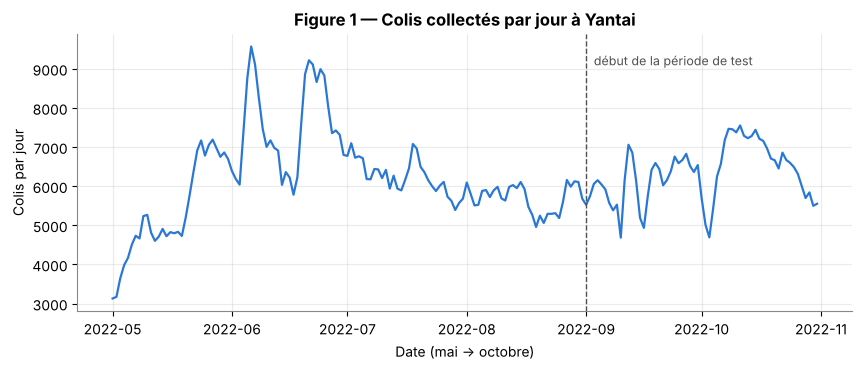

In [ ]:
# D.1 — Volume quotidien

vol = df.groupby(df.pickup_time.dt.normalize()).size()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(vol.index, vol.values, color=C_AVEC, lw=1.6)
ax.axvline(pd.Timestamp("2022-09-01"), color=C_GRIS, ls="--", lw=1)
ax.text(pd.Timestamp("2022-09-03"), vol.max() * 0.95, "début de la période de test", color=C_GRIS, fontsize=9)
ax.set(title="Figure 1 — Colis collectés par jour à Yantai", xlabel="Date (mai → octobre)", ylabel="Colis par jour")
sauver(fig, "fig01_volume_quotidien"); plt.show()
print(f"Moyenne : {vol.mean():.0f} colis/jour ; minimum {vol.min()} ; maximum {vol.max()}")

**Interprétation :** l'activité monte en mai, culmine en juin (deux pics proches de 9 500 colis/jour), puis se stabilise autour de 6 000 colis/jour en juillet–août. La période de test (septembre–octobre) oscille entre 4 700 et 7 500 colis/jour : elle reste comparable à l'apprentissage, ce qui rend le test du modèle représentatif.

### Figure 2 — Quelle est la taille d'une tournée ?

71 521 journées-coursier ; médiane 12 visites ; 34% ont entre 10 et 30 visites


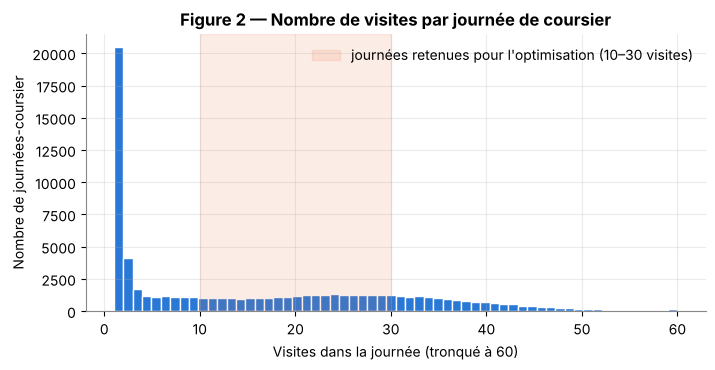

In [ ]:
# D.2 — Visites par journée-coursier

taille = visites.groupby(["courier_id", "ds"]).size()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(taille.clip(upper=60), bins=60, color=C_AVEC, edgecolor="white")
ax.axvspan(10, 30, color=C_SANS, alpha=0.12, label="journées retenues pour l'optimisation (10–30 visites)")
ax.set(title="Figure 2 — Nombre de visites par journée de coursier", xlabel="Visites dans la journée (tronqué à 60)",
       ylabel="Nombre de journées-coursier")
ax.legend(); sauver(fig, "fig02_taille_tournees"); plt.show()
print(f"{len(taille):,} journées-coursier ; médiane {taille.median():.0f} visites ; "
      f"{((taille >= 10) & (taille <= 30)).mean():.0%} ont entre 10 et 30 visites".replace(",", " "))

**Interprétation :** beaucoup de journées ne comptent qu'une ou deux visites (coursiers d'appoint), tandis qu'une large part des journées contient de **10 à 30 visites**. C'est là que l'ordre de visite compte vraiment : nous optimiserons ces journées.

### Figure 3 — Combien de temps entre deux visites ?

Médiane : 9 min ; 75 % des trajets durent moins de 15 min


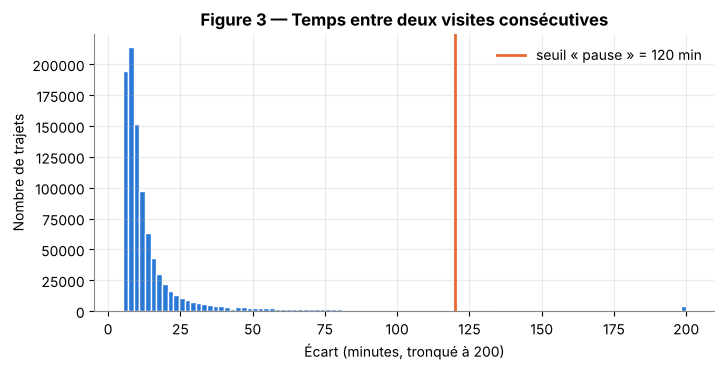

In [ ]:
# D.3 — Distribution de la cible

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(paires.ecart_min.clip(upper=200), bins=100, color=C_AVEC, edgecolor="white")
ax.axvline(SEUIL_PAUSE, color=C_SANS, lw=2, label=f"seuil « pause » = {SEUIL_PAUSE} min")
ax.set(title="Figure 3 — Temps entre deux visites consécutives", xlabel="Écart (minutes, tronqué à 200)",
       ylabel="Nombre de trajets"); ax.legend()
sauver(fig, "fig03_distribution_ecarts"); plt.show()
print(f"Médiane : {paires.ecart_min.median():.0f} min ; 75 % des trajets durent moins de {paires.ecart_min.quantile(.75):.0f} min")

**Interprétation :** la plupart des trajets durent une dizaine de minutes ; la queue au-delà de 2 h correspond à des pauses, exclues de l'apprentissage (C.5). Le minimum observé est de 5 minutes, ce qui reflète un temps de service minimal par visite.

### Figure 4 — La distance explique-t-elle le temps ?

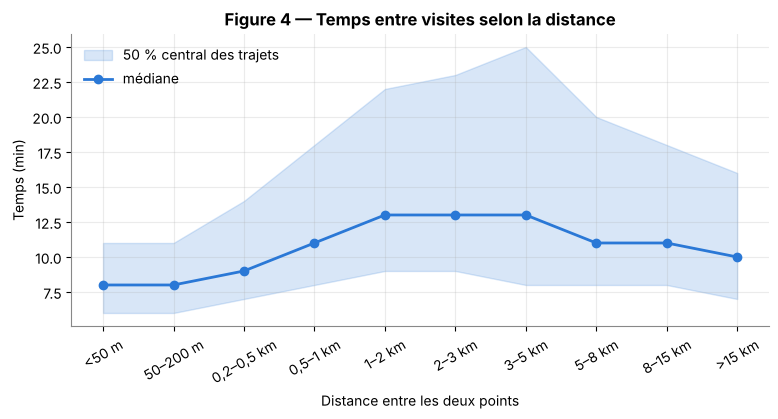

,trajets,médiane (min)
bande_dist,,
<50 m,75811.0,8.0
50–200 m,221310.0,8.0
"0,2–0,5 km",328453.0,9.0
"0,5–1 km",207897.0,11.0
1–2 km,93606.0,13.0
2–3 km,18828.0,13.0
3–5 km,9152.0,13.0
5–8 km,3151.0,11.0
8–15 km,940.0,11.0


In [ ]:
# D.4 — Temps vs distance

bornes = [0, 0.05, 0.2, 0.5, 1, 2, 3, 5, 8, 15, 100]
noms_bandes = ["<50 m", "50–200 m", "0,2–0,5 km", "0,5–1 km", "1–2 km", "2–3 km", "3–5 km", "5–8 km", "8–15 km", ">15 km"]
apprentissage["bande_dist"] = pd.cut(apprentissage.dist_km, bornes, labels=noms_bandes, include_lowest=True)
stat_dist = apprentissage.groupby("bande_dist", observed=False).ecart_min.describe(percentiles=[.25, .5, .75])
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(stat_dist))
ax.fill_between(x, stat_dist["25%"], stat_dist["75%"], color=C_AVEC, alpha=0.18, label="50 % central des trajets")
ax.plot(x, stat_dist["50%"], "o-", color=C_AVEC, lw=2, label="médiane")
ax.set_xticks(x, noms_bandes, rotation=30)
ax.set(title="Figure 4 — Temps entre visites selon la distance", xlabel="Distance entre les deux points",
       ylabel="Temps (min)"); ax.legend()
sauver(fig, "fig04_temps_vs_distance"); plt.show()
display(stat_dist[["count", "50%"]].rename(columns={"count": "trajets", "50%": "médiane (min)"}).round(1))

**Interprétation :** le temps médian passe de 8 min (moins de 50 m) à 13 min (1 à 5 km), puis **redescend** pour les longs trajets, probablement faits en véhicule sur des axes rapides. La relation n'est donc **ni proportionnelle ni linéaire** : même à moins de 50 m il faut plusieurs minutes (service, accès, attente du client), et à distance égale le temps varie énormément (bande bleue). Une formule « distance ÷ vitesse » ne capte pas cette forme ; c'est ce que le ML doit apprendre.

### Figure 5 — L'heure de la journée compte-t-elle ?

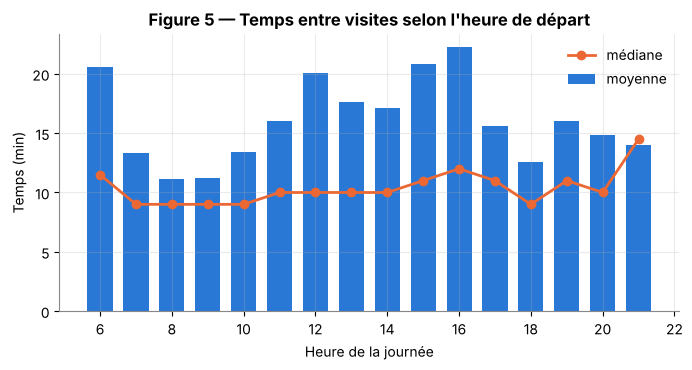

In [ ]:
# D.5 — Effet de l'heure

par_heure = apprentissage.assign(h=apprentissage.heure.astype(int)).query("6 <= h <= 21").groupby("h").ecart_min.agg(["median", "mean", "size"])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(par_heure.index, par_heure["mean"], color=C_AVEC, width=0.7, label="moyenne")
ax.plot(par_heure.index, par_heure["median"], "o-", color=C_SANS, lw=2, label="médiane")
ax.set(title="Figure 5 — Temps entre visites selon l'heure de départ", xlabel="Heure de la journée",
       ylabel="Temps (min)"); ax.legend()
sauver(fig, "fig05_effet_heure"); plt.show()

**Interprétation :** le matin (7 h – 10 h) les trajets sont rapides (environ 11 à 13 min en moyenne) ; entre 11 h et 16 h, le temps moyen monte jusqu'à environ 20 min, avec un pic à 16 h. La médiane bouge peu : ce sont surtout les **trajets longs ou interrompus** qui deviennent plus fréquents l'après-midi. **Conséquence pour l'optimisation :** la matrice de temps doit dépendre de l'heure. Le ML fournira donc une matrice **par heure** : une même tournée n'a pas le même coût à 9 h et à 16 h.

### Figure 6 — Le type de lieu influence-t-il le temps ?

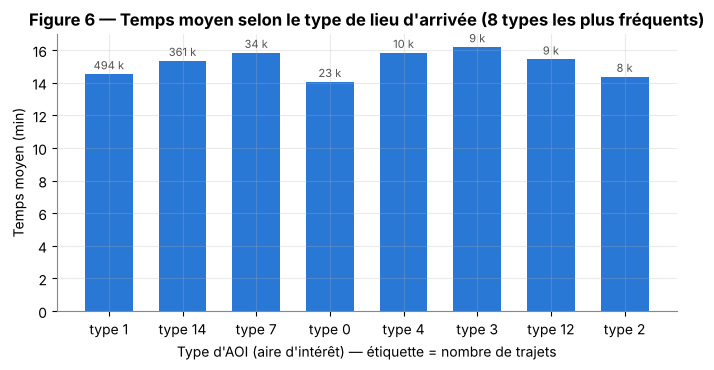

In [ ]:
# D.6 — Type d'AOI

par_type = apprentissage.groupby("aoi_type_arr").ecart_min.agg(["median", "mean", "size"]).sort_values("size", ascending=False).head(8)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar([f"type {i}" for i in par_type.index], par_type["mean"], color=C_AVEC, width=0.65)
for i, (m, n) in enumerate(zip(par_type["mean"], par_type["size"])):
    ax.text(i, m + 0.3, f"{n/1000:.0f} k", ha="center", fontsize=8, color=C_GRIS)
ax.set(title="Figure 6 — Temps moyen selon le type de lieu d'arrivée (8 types les plus fréquents)",
       xlabel="Type d'AOI (aire d'intérêt) — étiquette = nombre de trajets", ylabel="Temps moyen (min)")
sauver(fig, "fig06_type_aoi"); plt.show()

**Interprétation :** les écarts entre types de lieux sont **modestes** (de 14 à 16 min en moyenne). Le type d'AOI apporte une information, mais secondaire : nous le gardons comme variable explicative, et la Figure 13 confirmera son faible poids.

### Figure 7 — Les fenêtres horaires sont-elles respectées ?

En retard : 0.47% ; collectés avant le début de fenêtre : 31.6%


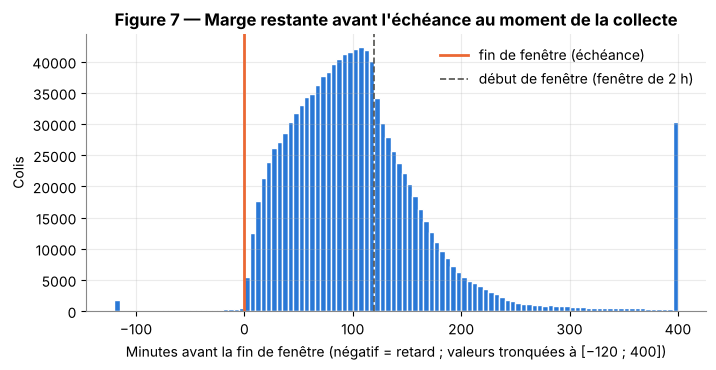

In [ ]:
# D.7 — Position de la collecte dans la fenêtre

marge = (df.time_window_end - df.pickup_time).dt.total_seconds() / 60
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(marge.clip(-120, 400), bins=104, color=C_AVEC, edgecolor="white")
ax.axvline(0, color=C_SANS, lw=2, label="fin de fenêtre (échéance)")
ax.axvline(120, color=C_GRIS, lw=1.2, ls="--", label="début de fenêtre (fenêtre de 2 h)")
ax.set(title="Figure 7 — Marge restante avant l'échéance au moment de la collecte",
       xlabel="Minutes avant la fin de fenêtre (négatif = retard ; valeurs tronquées à [−120 ; 400])", ylabel="Colis"); ax.legend()
sauver(fig, "fig07_fenetres_horaires"); plt.show()
print(f"En retard : {(marge < 0).mean():.2%} ; collectés avant le début de fenêtre : {(marge > duree_fen).mean():.1%}")

**Interprétation :** les coursiers réels **respectent presque toujours l'échéance** (moins de 1 % de retard), souvent avec une large marge, et un tiers des colis sont collectés **avant** le début de la fenêtre. Le gain à attendre de l'optimisation porte donc sur **le temps et la distance**, sans dégrader le respect des fenêtres (qui sera surveillé comme garde-fou).

### Figure 8 — Les tâches sont-elles connues dès le matin ?

Visites déjà connues avant la première collecte : 46%


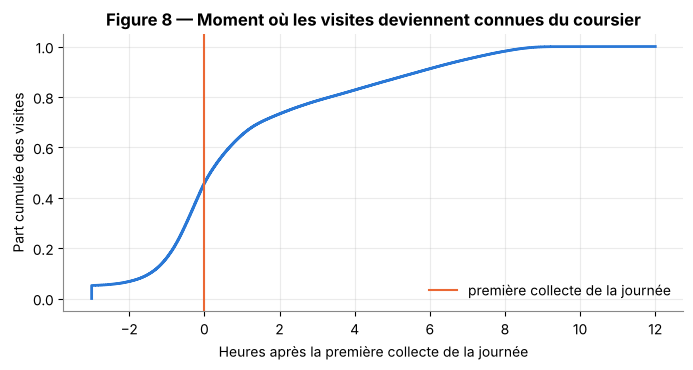

In [ ]:
# D.8 — Arrivée progressive des tâches

premier = visites.groupby(["courier_id", "ds"]).t_debut.transform("min")
avance = (visites.connue_a - premier).dt.total_seconds() / 3600
fig, ax = plt.subplots(figsize=(8, 3.6))
vals = np.sort(avance.clip(-3, 12)); ax.plot(vals, np.linspace(0, 1, len(vals)), color=C_AVEC, lw=2)
ax.axvline(0, color=C_SANS, lw=1.5, label="première collecte de la journée")
ax.set(title="Figure 8 — Moment où les visites deviennent connues du coursier",
       xlabel="Heures après la première collecte de la journée", ylabel="Part cumulée des visites")
ax.legend(); sauver(fig, "fig08_arrivee_taches"); plt.show()
print(f"Visites déjà connues avant la première collecte : {(avance <= 0).mean():.0%}")

**Interprétation :** moins de la moitié des visites sont connues avant la première collecte ; les autres arrivent au fil de la journée. **C'est une découverte méthodologique majeure :** planifier toute la journée dès le matin serait irréaliste (ce serait « tricher » en utilisant des informations futures). Nous optimiserons donc **de manière dynamique** : à chaque arrêt, le coursier replanifie parmi les seules tâches déjà connues.

### Figure 9 — Où se trouvent les points de collecte ?

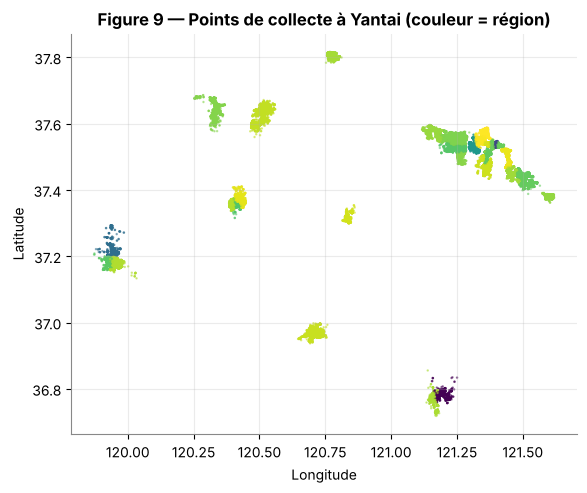

In [ ]:
# D.9 — Carte des points de collecte

ech = visites.sample(60000, random_state=SEED)
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.scatter(ech.lng, ech.lat, s=0.6, c=ech.region_id, cmap="viridis", alpha=0.5)
ax.set(title="Figure 9 — Points de collecte à Yantai (couleur = région)", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect(1 / np.cos(np.radians(37.4)))
sauver(fig, "fig09_carte_points"); plt.show()

**Interprétation :** les collectes se concentrent dans plusieurs pôles urbains séparés, chacun servi par des régions différentes. Les distances entre deux points d'une même tournée sont donc surtout **locales** ; la géographie de la région (`region_id`, coordonnées) est une information utile au modèle.

### Figure 10 — Corrélations entre les variables

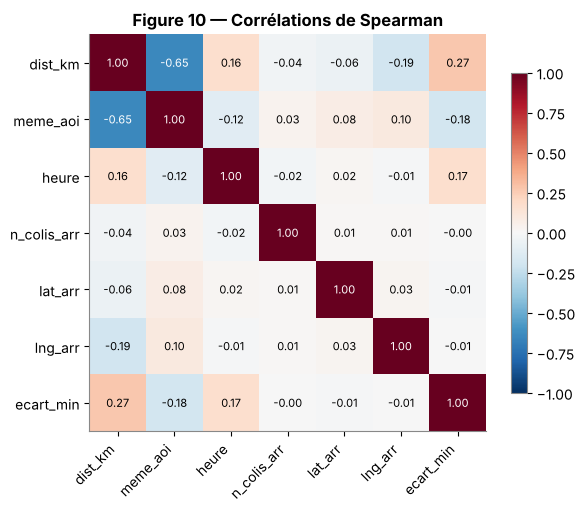

In [ ]:
# D.10 — Corrélations
cols_corr = ["dist_km", "meme_aoi", "heure", "n_colis_arr", "lat_arr", "lng_arr", "ecart_min"]
corr = apprentissage[cols_corr].sample(200000, random_state=SEED).corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_corr)), cols_corr, rotation=45, ha="right"); ax.set_yticks(range(len(cols_corr)), cols_corr)
for i in range(len(cols_corr)):
    for j in range(len(cols_corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Figure 10 — Corrélations de Spearman")
sauver(fig, "fig10_correlations"); plt.show()

**Interprétation :** la distance (0,27) et l'heure (0,17) sont les variables les plus liées au temps ; le fait d'être dans la même AOI va dans le sens inverse (−0,18 : trajets courts). Toutes ces corrélations restent **faibles** : aucune variable seule n'explique le temps. C'est un argument pour un modèle **non linéaire** qui combine plusieurs variables, et un signe que la prédiction restera difficile.

In [ ]:
# D.11 — Export des données de l'EDA pour la plateforme web
hist_ecarts, bords = np.histogram(paires.ecart_min.clip(upper=200), bins=40, range=(0, 200))
hist_marge, bords_m = np.histogram(marge.clip(-120, 400), bins=52, range=(-120, 400))
hist_taille, bords_t = np.histogram(taille.clip(upper=60), bins=60, range=(1, 61))
eda = {
    "volume_quotidien": {"dates": [d.strftime("%m-%d") for d in vol.index], "colis": vol.astype(int).tolist()},
    "hist_ecarts": {"bords": bords.tolist(), "valeurs": hist_ecarts.tolist()},
    "temps_vs_distance": {"bandes": noms_bandes, "q25": stat_dist["25%"].round(2).tolist(),
                          "mediane": stat_dist["50%"].round(2).tolist(), "q75": stat_dist["75%"].round(2).tolist(),
                          "n": stat_dist["count"].astype(int).tolist()},
    "par_heure": {"heures": par_heure.index.tolist(), "moyenne": par_heure["mean"].round(2).tolist(),
                  "mediane": par_heure["median"].round(2).tolist(), "n": par_heure["size"].astype(int).tolist()},
    "par_type_aoi": {"types": [int(i) for i in par_type.index], "moyenne": par_type["mean"].round(2).tolist(),
                     "n": par_type["size"].astype(int).tolist()},
    "hist_marge": {"bords": bords_m.tolist(), "valeurs": hist_marge.tolist()},
    "hist_taille": {"bords": bords_t.tolist(), "valeurs": hist_taille.tolist()},
    "correlations": {"variables": cols_corr, "matrice": corr.round(3).values.tolist()},
    "points_carte": ech.sample(4000, random_state=SEED)[["lng", "lat", "region_id"]].round(5).values.tolist(),
    "indicateurs": {
        "colis": int(len(raw)), "colonnes": int(raw.shape[1]), "coursiers": int(raw.courier_id.nunique()),
        "regions": int(raw.region_id.nunique()), "aoi": int(raw.aoi_id.nunique()), "jours": int(raw.ds.nunique()),
        "journees_coursier": int(len(taille)), "visites": int(len(visites)),
        "paires_causales": int(len(paires)), "paires_apprentissage": int(len(apprentissage)),
        "taux_retard_reel": float((marge < 0).mean()), "taux_avant_fenetre": float((marge > duree_fen).mean()),
        "part_connue_avant_debut": float((avance <= 0).mean()), "ecart_median": float(paires.ecart_min.median()),
        "fenetre_mediane_min": float(duree_fen.median()),
    },
    "valeurs_manquantes": {c: int(v) for c, v in raw.isna().sum().items()},
    "journal_preprocessing": journal,
}
print("Indicateurs clés exportés :", json.dumps(eda["indicateurs"], indent=1, ensure_ascii=False))

Indicateurs clés exportés : {
 "colis": 1146781,
 "colonnes": 19,
 "coursiers": 2593,
 "regions": 30,
 "aoi": 6024,
 "jours": 184,
 "journees_coursier": 71521,
 "visites": 1135167,
 "paires_causales": 976050,
 "paires_apprentissage": 959503,
 "taux_retard_reel": 0.004707088798994751,
 "taux_avant_fenetre": 0.3159748897130315,
 "part_connue_avant_debut": 0.4597120952247555,
 "ecart_median": 9.0,
 "fenetre_mediane_min": 120.0
}


## E. Machine Learning

### E.1 Définition du problème
* **y (cible)** : `ecart_min`, le temps en minutes entre la fin d'une visite et le début de la suivante.
* **X** : les 9 variables présentées en C.4.
* **Type de problème** : régression ; métriques **MAE** (erreur moyenne en minutes, la plus parlante), **RMSE** (pénalise les grosses erreurs) et **R²** (part de la variabilité expliquée).

### E.2 Baseline : la formule « traditionnelle »
C'est ce qu'utiliserait un planificateur sans ML, à partir de **moyennes historiques** :

**temps = temps de service médian + distance ÷ vitesse médiane**

Les deux paramètres sont estimés sur les données d'entraînement uniquement.

In [ ]:
# E.2 — Baseline « historique » (formule sans ML)

SERVICE_MED = float(train.loc[train.dist_km < 0.05, CIBLE].median())          # minutes
loin = train[train.dist_km > 0.3]
VITESSE_MED = float(np.median(loin.dist_km / np.maximum(loin[CIBLE] - SERVICE_MED, 1.0)))   # km/min

def prediction_baseline(dist_km):
    return SERVICE_MED + np.asarray(dist_km) / VITESSE_MED

print(f"Temps de service médian : {SERVICE_MED:.1f} min")
print(f"Vitesse médiane         : {VITESSE_MED * 60:.1f} km/h")

Temps de service médian : 8.0 min
Vitesse médiane         : 16.7 km/h


### E.3 Modèles candidats
Nous comparons, du plus simple au plus flexible :
1. **Régression linéaire** — simple et explicable : un coefficient par variable.
2. **Arbre de décision** (profondeur 10) — des règles « si… alors… » lisibles.
3. **Random Forest** — moyenne de nombreux arbres : robuste.
4. **Gradient Boosting** (`HistGradientBoostingRegressor`) — des arbres construits successivement, chacun corrigeant les erreurs du précédent ; rapide sur de gros volumes.

La Random Forest est entraînée sur un échantillon de 150 000 paires pour rester rapide dans Colab ; les autres modèles utilisent toutes les paires d'entraînement.

In [ ]:
# E.3 — Entraînement et comparaison

num = [f for f in FEATURES if f not in CATEGORIELLES]
lineaire = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORIELLES),
                       ("num", StandardScaler(), num)]),
    LinearRegression())
modeles = {
    "Régression linéaire": lineaire,
    "Arbre de décision": DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=16, min_samples_leaf=20,
                                           n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, max_leaf_nodes=63,
                                                       categorical_features=[FEATURES.index(c) for c in CATEGORIELLES],
                                                       random_state=SEED),
}

def evaluer(nom, y_vrai, y_pred, duree=0.0):
    return {"modele": nom, "MAE": mean_absolute_error(y_vrai, y_pred),
            "Biais": float(np.mean(np.asarray(y_pred) - np.asarray(y_vrai))),
            "RMSE": math.sqrt(mean_squared_error(y_vrai, y_pred)), "R2": r2_score(y_vrai, y_pred),
            "temps_entrainement_s": duree}

resultats, predictions = [], {}
predictions["Baseline (moyennes historiques)"] = prediction_baseline(X_test.dist_km)
resultats.append(evaluer("Baseline (moyennes historiques)", y_test, predictions["Baseline (moyennes historiques)"]))
for nom, modele in modeles.items():
    t0 = time.time()
    if nom == "Random Forest":
        idx = train.sample(150000, random_state=SEED).index
        modele.fit(X_train.loc[idx], y_train.loc[idx])
    else:
        modele.fit(X_train, y_train)
    duree = time.time() - t0
    predictions[nom] = modele.predict(X_test)
    resultats.append(evaluer(nom, y_test, predictions[nom], duree))
    print(f"{nom:<22} entraîné en {duree:5.1f} s")

tableau_ml = pd.DataFrame(resultats).set_index("modele")
display(tableau_ml.round(3))
print(f"Temps moyen réel entre deux visites (test) : {y_test.mean():.2f} min ; médiane : {y_test.median():.0f} min")

Régression linéaire    entraîné en   2.4 s
Arbre de décision      entraîné en   1.9 s
Random Forest          entraîné en  20.2 s
Gradient Boosting      entraîné en   5.6 s
Temps moyen réel entre deux visites (test) : 15.05 min ; médiane : 9 min


,MAE,Biais,RMSE,R2,temps_entrainement_s
modele,,,,,
Baseline (moyennes historiques),7.977,-5.071,17.777,-0.104,0.000
Régression linéaire,9.392,-0.134,16.554,0.043,2.357
Arbre de décision,9.237,-0.070,16.248,0.078,1.861
Random Forest,9.105,-0.056,16.039,0.101,20.154
Gradient Boosting,9.013,-0.044,15.919,0.115,5.615


**Lecture du tableau — un résultat contre-intuitif mais instructif :**
* La **baseline a la plus petite MAE** : elle prédit un temps « typique » (proche de la médiane, 9 min). Comme la plupart des trajets sont courts, elle se trompe peu *en général*.
* Mais elle a un **biais fortement négatif** : en moyenne, elle **sous-estime** chaque trajet de plusieurs minutes, car elle ignore la longue queue des trajets lents (Figure 3).
* Les modèles ML ont une MAE un peu plus élevée, mais une **RMSE plus faible**, un **R² positif** et un **biais quasi nul** : en moyenne, ils prédisent juste.

**Pourquoi le biais compte plus que la MAE pour notre décision :** une tournée additionne une vingtaine de trajets. Une sous-estimation de quelques minutes par trajet devient **plus d'une heure d'erreur** à la fin de la journée : un plan « trop optimiste » rate des échéances. Pour l'optimisation, il faut donc des temps **non biaisés**.

**Critère de sélection :** parmi les modèles ML, nous retenons celui qui a la **plus faible RMSE** (et donc le meilleur R²), à condition que son biais soit proche de zéro.

> Le R² reste modeste (≈ 0,1) : une grande part du temps entre deux visites dépend d'éléments absents des données (attente du client, appel, livraisons faites entre deux collectes). C'est une limite honnête du dataset, pas une erreur de méthode.

### E.4 Comparaison visuelle des performances

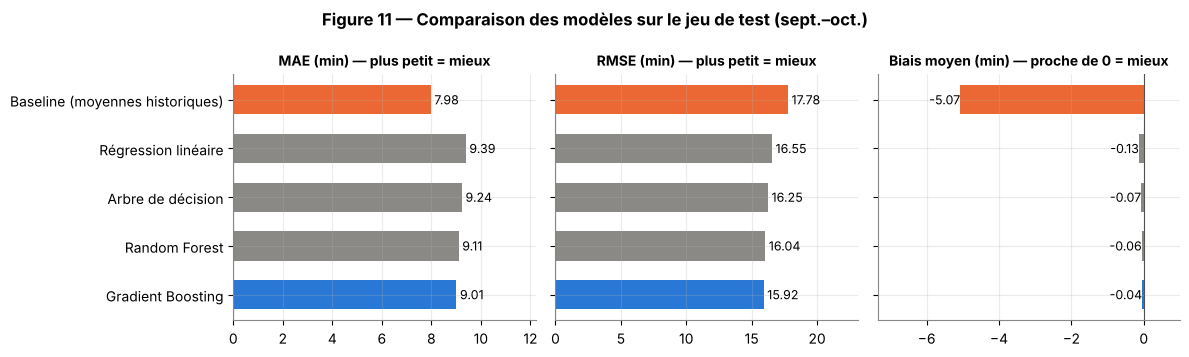

In [ ]:
# E.4 — Graphique de comparaison des modèles

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
couleurs = [C_SANS] + [C_REEL] * 3 + [C_AVEC]
for ax, col, titre in zip(axes, ["MAE", "RMSE", "Biais"],
                          ["MAE (min) — plus petit = mieux", "RMSE (min) — plus petit = mieux", "Biais moyen (min) — proche de 0 = mieux"]):
    vals = tableau_ml[col]
    ax.barh(tableau_ml.index, vals, color=couleurs, height=0.6)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
    ax.set_title(titre, fontsize=10); ax.axvline(0, color=C_GRIS, lw=0.8)
    lo, hi = min(0, vals.min()), vals.max()
    ax.set_xlim(lo * 1.45 if lo < 0 else 0, hi * 1.3 if hi > 0 else 1)
axes[0].invert_yaxis()
fig.suptitle("Figure 11 — Comparaison des modèles sur le jeu de test (sept.–oct.)", fontweight="bold")
fig.tight_layout(); sauver(fig, "fig11_comparaison_modeles"); plt.show()

### E.5 Analyse des erreurs
Où le modèle se trompe-t-il le plus ? Nous comparons l'erreur du meilleur modèle et de la baseline **par tranche de distance**.

Modèle retenu : Gradient Boosting
Erreur cumulée attendue de la baseline sur une tournée de 20 trajets : -101 min
Erreur cumulée attendue du modèle retenu sur 20 trajets            : -1 min


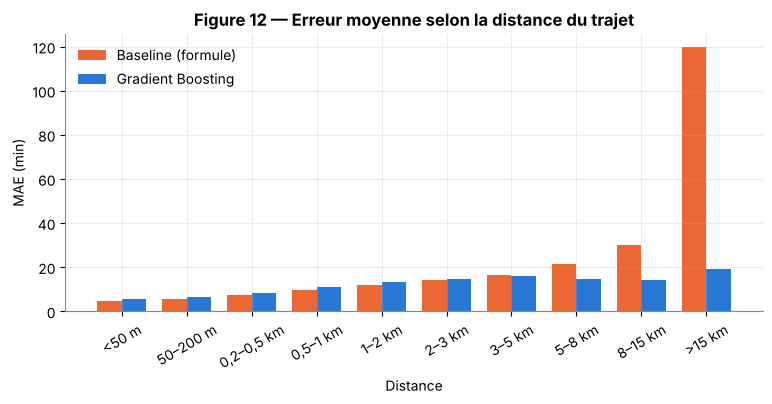

In [ ]:
# E.5 — Erreurs par tranche de distance

NOM_FINAL = tableau_ml.drop(index="Baseline (moyennes historiques)").RMSE.idxmin()
modele_final = modeles[NOM_FINAL]
err = pd.DataFrame({"bande": test.bande_dist if "bande_dist" in test else pd.cut(test.dist_km, bornes, labels=noms_bandes, include_lowest=True),
                    "ml": np.abs(predictions[NOM_FINAL] - y_test),
                    "base": np.abs(predictions["Baseline (moyennes historiques)"] - y_test)})
err_bande = err.groupby("bande", observed=False)[["base", "ml"]].mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(err_bande)); w = 0.38
ax.bar(x - w / 2, err_bande.base, w, color=C_SANS, label="Baseline (formule)")
ax.bar(x + w / 2, err_bande.ml, w, color=C_AVEC, label=NOM_FINAL)
ax.set_xticks(x, err_bande.index, rotation=30)
ax.set(title="Figure 12 — Erreur moyenne selon la distance du trajet", xlabel="Distance", ylabel="MAE (min)"); ax.legend()
sauver(fig, "fig12_erreurs_par_distance"); plt.show()
print("Modèle retenu :", NOM_FINAL)
biais_route = 20 * tableau_ml.loc["Baseline (moyennes historiques)", "Biais"]
print(f"Erreur cumulée attendue de la baseline sur une tournée de 20 trajets : {biais_route:.0f} min")
print(f"Erreur cumulée attendue du modèle retenu sur 20 trajets            : {20 * tableau_ml.loc[NOM_FINAL, 'Biais']:+.0f} min")

**Lecture :** sur les trajets courts (moins de 2 km, la grande majorité), la formule fait aussi bien ou un peu mieux que le ML, car elle prédit le trajet « typique ». Au-delà de 5 km, la formule se trompe énormément : elle applique une vitesse de vélo à des trajets faits en véhicule, et son erreur dépasse 100 min au-delà de 15 km. Le ML reste stable, autour de 15 à 20 min. **Le ML est surtout utile pour éviter les grosses erreurs**, et ce sont justement elles qui faussent une tournée.

### E.6 Interprétation : quelles variables comptent ?
Nous utilisons l'**importance par permutation** : on mélange une variable au hasard et on mesure combien l'erreur augmente. Plus l'erreur augmente, plus la variable est importante.

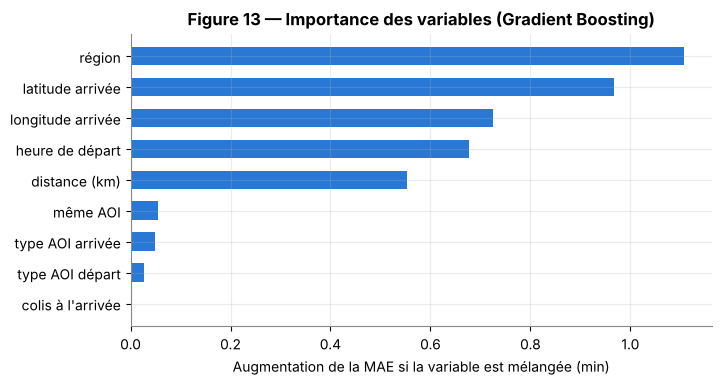

In [ ]:
# E.6 — Importance des variables (permutation)

ech_test = test.sample(20000, random_state=SEED)
imp = permutation_importance(modele_final, ech_test[FEATURES], ech_test[CIBLE], n_repeats=5,
                             random_state=SEED, scoring="neg_mean_absolute_error", n_jobs=1)
importances = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
noms_lisibles = {"dist_km": "distance (km)", "meme_aoi": "même AOI", "aoi_type_dep": "type AOI départ",
                 "aoi_type_arr": "type AOI arrivée", "heure": "heure de départ", "n_colis_arr": "colis à l'arrivée",
                 "region_id": "région", "lat_arr": "latitude arrivée", "lng_arr": "longitude arrivée"}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh([noms_lisibles[f] for f in importances.index], importances.values, color=C_AVEC, height=0.6)
ax.set(title=f"Figure 13 — Importance des variables ({NOM_FINAL})",
       xlabel="Augmentation de la MAE si la variable est mélangée (min)")
sauver(fig, "fig13_importance_variables"); plt.show()

**Lecture :** la **localisation** (région, latitude, longitude) et l'**heure** pèsent le plus, devant la distance elle-même. Le modèle a appris que certains quartiers sont plus lents que d'autres (densité, accès, circulation), et que l'après-midi est plus lent. Le type d'AOI compte peu, et le nombre de colis à l'arrivée ne compte pas : presque chaque visite ne contient qu'un seul colis (1,01 en moyenne).

### E.7 Sélection du modèle final et modèle évaluateur
Le modèle retenu est celui qui a la **plus faible MAE sur le test**. Il servira de **planificateur** dans l'optimisation.

Nous entraînons ensuite, avec le même algorithme, le **modèle évaluateur** sur les coursiers B. Il ne sert qu'à **noter** les tournées (« réalité simulée »). On vérifie aussi sa précision sur le jeu de test.

In [ ]:
# E.7 — Modèle évaluateur indépendant

evaluateur = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, max_leaf_nodes=63,
                                           categorical_features=[FEATURES.index(c) for c in CATEGORIELLES],
                                           random_state=SEED + 1)
evaluateur.fit(evaluateur_data[FEATURES], evaluateur_data[CIBLE])
mae_eval = mean_absolute_error(y_test, evaluateur.predict(X_test))
print(f"MAE de l'évaluateur (coursiers B) sur le test des coursiers A : {mae_eval:.2f} min")

resultats_ml = {
    "modeles": tableau_ml.reset_index().round(4).to_dict(orient="records"),
    "modele_final": NOM_FINAL,
    "baseline": {"service_median_min": SERVICE_MED, "vitesse_mediane_kmh": VITESSE_MED * 60},
    "importances": {noms_lisibles[k]: float(v) for k, v in importances.sort_values(ascending=False).items()},
    "erreurs_par_distance": {"bandes": [str(b) for b in err_bande.index], "baseline": err_bande.base.round(3).tolist(),
                             "ml": err_bande.ml.round(3).tolist()},
    "evaluateur_mae": mae_eval,
    "tailles": {"train": int(len(train)), "test": int(len(test)), "evaluateur": int(len(evaluateur_data))},
    "features": FEATURES,
}

MAE de l'évaluateur (coursiers B) sur le test des coursiers A : 9.48 min


## F. Optimisation logistique — partie centrale

**Logique :** Données → Modèle ML → **matrice de temps prédits** → **optimisation de l'ordre de visite** → évaluation des gains.

### F.1 Le modèle mathématique (problème statique à un instant donné)
À un instant τ, le coursier est au point 0 et connaît un ensemble *N* de visites en attente. On cherche l'ordre de visite qui minimise :

$$\min \; \sum_{i}\sum_{j} \hat t_{ij}\,x_{ij} \;+\; \lambda \sum_{j \in N} L_j$$

sous les contraintes :

$$\sum_{i} x_{ij} = 1 \;\; \forall j \in N \qquad \text{(on arrive une fois à chaque visite)}$$
$$\sum_{j} x_{ij} = 1 \;\; \forall i \in N \cup \{0\} \qquad \text{(on repart une fois — le dernier arc va vers un nœud fictif de fin)}$$
$$a_j \;\ge\; a_i + \hat t_{ij} - M\,(1 - x_{ij}) \qquad \text{(propagation du temps ; supprime aussi les sous-tours)}$$
$$L_j \;\ge\; a_j - l_j,\quad L_j \ge 0,\quad a_0 = \tau,\quad x_{ij} \in \{0,1\}$$

* **Variables de décision :** $x_{ij}$ (aller de *i* à *j* : oui/non), $a_j$ (heure d'arrivée), $L_j$ (retard).
* **Paramètres :** $\hat t_{ij}$ = temps **prédit par le ML** ; $l_j$ = échéance (fin de fenêtre) ; λ = coût d'une minute de retard, exprimé en minutes de trajet.
* **Type :** programme linéaire **mixte en nombres entiers (MILP)**, variante du **TSP avec fenêtres horaires (TSPTW)** — NP-difficile.

### F.2 La version dynamique (réaliste)
Comme les tâches arrivent pendant la journée (Figure 8), on résout ce problème **à chaque arrêt** (*rolling horizon*) :
1. le coursier termine une visite à l'instant τ ;
2. on construit la liste des visites **déjà connues** et non encore faites ;
3. si elle est vide, il attend la prochaine tâche ;
4. sinon, on optimise l'ordre de ces visites ; le coursier part vers la **première** de la liste ;
5. on recommence à l'arrêt suivant, avec les nouvelles tâches éventuellement arrivées.

### F.3 Méthodes de résolution
* **Heuristique** (utilisée à chaque arrêt, très rapide) : construction **gloutonne** (aller vers la visite qui coûte le moins tout de suite), puis amélioration locale **2-opt** (inverser un segment de la tournée) et **or-opt** (déplacer une visite ailleurs), répétées jusqu'à ce qu'aucune amélioration ne soit possible.
* **MILP exact** avec le solveur **HiGHS** (`scipy.optimize.milp`) sur des instances de 8 visites, pour **mesurer l'écart** entre l'heuristique et l'optimum prouvé.

La matrice de temps dépend de l'heure (Figure 5) : $\hat t_{ij}$ est lue dans la matrice de l'heure de départ.

In [ ]:
# F.3 — Heuristique d'optimisation

H0, H1 = 6, 22                     # matrices horaires de 6 h à 22 h

def idx_heure(tau):
    """tau en minutes depuis minuit -> indice de la matrice horaire."""
    return min(max(int(tau // 60), H0), H1) - H0

def cout_route(route, depart, tau, M, ech, lam):
    """Coût = somme des temps prédits + lam × retards, en suivant l'heure."""
    t, cout, prec = tau, 0.0, depart
    for j in route:
        d = M[idx_heure(t)][prec][j]
        t += d
        cout += d + lam * max(0.0, t - ech[j])
        prec = j
    return cout

def planifier(depart, tau, attente, M, ech, lam, max_passes=50):
    """Glouton + 2-opt + or-opt (amélioration de premier niveau)."""
    route, restant, t, prec = [], list(attente), tau, depart
    while restant:                                      # 1) construction gloutonne
        meilleur, mcout = None, float("inf")
        for j in restant:
            d = M[idx_heure(t)][prec][j]
            c = d + lam * max(0.0, t + d - ech[j])
            if c < mcout - 1e-12:
                meilleur, mcout = j, c
        route.append(meilleur); restant.remove(meilleur)
        t += M[idx_heure(t)][prec][meilleur]; prec = meilleur
    best = cout_route(route, depart, tau, M, ech, lam)
    n = len(route)
    for _ in range(max_passes):                         # 2) amélioration locale
        ameliore = False
        for i in range(n - 1):                          # 2-opt : inverser route[i..k]
            for k in range(i + 1, n):
                cand = route[:i] + route[i:k + 1][::-1] + route[k + 1:]
                c = cout_route(cand, depart, tau, M, ech, lam)
                if c < best - 1e-9:
                    route, best, ameliore = cand, c, True
        for i in range(n):                              # or-opt : déplacer une visite
            for k in range(n):
                if k == i:
                    continue
                cand = route[:i] + route[i + 1:]
                cand.insert(k, route[i])
                c = cout_route(cand, depart, tau, M, ech, lam)
                if c < best - 1e-9:
                    route, best, ameliore = cand, c, True
        if not ameliore:
            break
    return route, best

print("Heuristique prête.")

Heuristique prête.


### F.4 Sélection des journées de test et construction des matrices
Nous retenons des journées **de test** (sept.–oct.) des coursiers **A**, avec 10 à 30 visites. Pour chacune, nous calculons trois matrices horaires (6 h → 22 h) :
* **sans ML** : la formule baseline (service médian + distance ÷ vitesse médiane) ;
* **avec ML** : les prédictions du modèle planificateur ;
* **évaluateur** : les prédictions du modèle indépendant (coursiers B), utilisées **uniquement pour noter** les tournées.

In [ ]:
# F.4 — Journées de test et matrices de temps
N_JOURNEES = 150
taille_v = visites.groupby(["courier_id", "ds"]).size().rename("n").reset_index()
cand = taille_v[(taille_v.n >= 10) & (taille_v.n <= 30) & taille_v.courier_id.isin(groupe_A)
                & (taille_v.ds >= 901)]
journees = cand.sample(N_JOURNEES, random_state=SEED).sort_values(["ds", "courier_id"])[["courier_id", "ds"]]
print(f"Journées candidates : {len(cand)} ; journées simulées : {len(journees)}")

HEURES = np.arange(H0, H1 + 1)

def matrices_journee(v):
    """Retourne (sans_ml, avec_ml, evaluateur) de forme (heures, n, n), en minutes."""
    n = len(v)
    I, J = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    I, J = I.ravel(), J.ravel()
    dist = haversine_km(v.lng.values[I], v.lat.values[I], v.lng.values[J], v.lat.values[J])
    base = prediction_baseline(dist).reshape(n, n)
    lignes = []
    for h in HEURES:
        lignes.append(pd.DataFrame({
            "dist_km": dist, "meme_aoi": (v.aoi_id.values[I] == v.aoi_id.values[J]).astype(float),
            "aoi_type_dep": v.aoi_type.values[I], "aoi_type_arr": v.aoi_type.values[J], "heure": h + 0.5,
            "n_colis_arr": v.n_colis.values[J], "region_id": v.region_id.values[J],
            "lat_arr": v.lat.values[J], "lng_arr": v.lng.values[J]}))
    Xm = pd.concat(lignes, ignore_index=True)[FEATURES]
    ml = modele_final.predict(Xm).reshape(len(HEURES), n, n)
    ev = evaluateur.predict(Xm).reshape(len(HEURES), n, n)
    sans = np.repeat(base[None], len(HEURES), axis=0)
    for M in (ml, ev, sans):
        M[:, np.arange(n), np.arange(n)] = 0.0
        np.maximum(M, 1.0, out=M, where=~np.eye(n, dtype=bool)[None].repeat(len(HEURES), 0))
    dist_mat = np.round(dist.reshape(n, n), 4)
    # Arrondi au centième de minute : ce sont EXACTEMENT ces valeurs que le simulateur web utilisera
    return np.round(sans, 2), np.round(ml, 2), np.round(ev, 2), dist_mat

instances = []
t0 = time.time()
for cid, ds in journees.itertuples(index=False):
    v = visites[(visites.courier_id == cid) & (visites.ds == ds)].sort_values("visite").reset_index(drop=True)
    minuit = v.t_debut.iloc[0].normalize()
    m = lambda s: ((s - minuit).dt.total_seconds() / 60).values
    sans, ml, ev, dist_mat = matrices_journee(v)
    instances.append({"courier_id": int(cid), "ds": int(ds), "n": len(v), "v": v,
                      "connue": m(v.connue_a), "echeance": m(v.echeance), "debut": m(v.t_debut), "fin": m(v.t_fin),
                      "M_sans": sans.tolist(), "M_ml": ml.tolist(), "M_eval": ev.tolist(), "dist": dist_mat.tolist()})
print(f"Matrices calculées pour {len(instances)} journées en {time.time() - t0:.0f} s")

Journées candidates : 3838 ; journées simulées : 150
Matrices calculées pour 150 journées en 28 s


### F.5 Simulation : réel vs sans ML vs avec ML
Les trois stratégies partent de la **même première visite, à la même heure** (celle de la réalité).
* **Réel** : on rejoue l'ordre réel du coursier.
* **Sans ML / Avec ML** : à chaque arrêt, l'heuristique replanifie avec sa propre matrice de temps.

Dans tous les cas, **le temps qui s'écoule réellement est donné par l'évaluateur indépendant**, et aucune visite ne peut être faite avant d'être connue. La **distance** est calculée exactement (Haversine) : elle ne dépend d'aucun modèle.

**Hypothèse de pénalité :** λ = 5 (une minute de retard « coûte » autant que 5 minutes de trajet). Une analyse de sensibilité suit en F.8.

In [ ]:
# F.5 — Simulateur dynamique
LAMBDA = 5.0

def simuler(inst, strategie, lam=LAMBDA, toutes_connues=False):
    """strategie : 'reel', 'sans_ml' ou 'avec_ml'. Retourne les KPI et l'ordre suivi."""
    E, D, ech = inst["M_eval"], inst["dist"], inst["echeance"]
    connue = np.full(inst["n"], -1e9) if toutes_connues else inst["connue"]
    Mplan = inst["M_sans"] if strategie == "sans_ml" else inst["M_ml"]
    n = inst["n"]
    cur, tau = 0, float(inst["fin"][0])          # départ commun : fin réelle de la 1re visite
    t_start = tau
    faites, ordre = {0}, [0]
    deplacement = attente = distance = retard_min = 0.0
    n_retard = 1 if inst["fin"][0] > ech[0] else 0
    reel_suivant = iter(range(1, n))
    while len(faites) < n:
        if strategie == "reel":
            nxt = next(reel_suivant)
            if connue[nxt] > tau:
                attente += connue[nxt] - tau; tau = float(connue[nxt])
        else:
            dispo = [j for j in range(n) if j not in faites and connue[j] <= tau]
            if not dispo:
                prochaine = min(connue[j] for j in range(n) if j not in faites)
                attente += prochaine - tau; tau = float(prochaine)
                continue
            route, _ = planifier(cur, tau, dispo, Mplan, ech, lam)
            nxt = route[0]
        d = E[idx_heure(tau)][cur][nxt]
        tau += d; deplacement += d; distance += D[cur][nxt]
        if tau > ech[nxt]:
            n_retard += 1; retard_min += tau - ech[nxt]
        faites.add(nxt); ordre.append(nxt); cur = nxt
    return {"deplacement_min": deplacement, "attente_min": attente, "duree_min": tau - t_start,
            "distance_km": distance, "n_retard": n_retard, "retard_min": retard_min, "ordre": ordre}

t0 = time.time()
lignes = []
for k, inst in enumerate(instances):
    res = {s: simuler(inst, s) for s in ("reel", "sans_ml", "avec_ml")}
    inst["resultats"] = res
    vrai = inst["fin"][-1] - inst["fin"][0]
    for s, r in res.items():
        lignes.append({"journee": k, "courier_id": inst["courier_id"], "ds": inst["ds"], "n": inst["n"],
                       "strategie": s, "duree_reelle_observee": vrai,
                       **{c: r[c] for c in ("deplacement_min", "attente_min", "duree_min", "distance_km", "n_retard", "retard_min")}})
sim = pd.DataFrame(lignes)
print(f"Simulation de {len(instances)} journées × 3 stratégies en {time.time() - t0:.0f} s")

Simulation de 150 journées × 3 stratégies en 6 s


### F.6 Validation de l'évaluateur : la « réalité simulée » est-elle crédible ?
On compare, pour l'ordre **réel**, la durée **simulée** par l'évaluateur à la durée **réellement observée** dans les données.

Durée simulée / durée observée (total) : 0.89
Corrélation par journée                : 0.61
Erreur relative médiane par journée    : 8.8%
Retards par journée — observés dans les données : 0.08 ; simulés pour l'ordre réel : 1.05


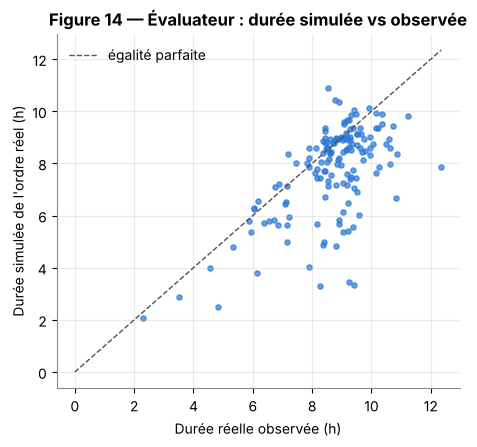

In [ ]:
# F.6 — Ancrage dans la réalité
reel = sim[sim.strategie == "reel"]
ratio = reel.duree_min.sum() / reel.duree_reelle_observee.sum()
corr_duree = np.corrcoef(reel.duree_min, reel.duree_reelle_observee)[0, 1]
err_duree = np.median(np.abs(reel.duree_min - reel.duree_reelle_observee) / reel.duree_reelle_observee)
print(f"Durée simulée / durée observée (total) : {ratio:.2f}")
print(f"Corrélation par journée                : {corr_duree:.2f}")
print(f"Erreur relative médiane par journée    : {err_duree:.1%}")
retards_obs = [int((inst["fin"] > inst["echeance"]).sum()) for inst in instances]
print(f"Retards par journée — observés dans les données : {np.mean(retards_obs):.2f} ; simulés pour l'ordre réel : {reel.n_retard.mean():.2f}")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(reel.duree_reelle_observee / 60, reel.duree_min / 60, s=14, color=C_AVEC, alpha=0.7)
lim = max(reel.duree_reelle_observee.max(), reel.duree_min.max()) / 60
ax.plot([0, lim], [0, lim], color=C_GRIS, ls="--", lw=1, label="égalité parfaite")
ax.set(title="Figure 14 — Évaluateur : durée simulée vs observée", xlabel="Durée réelle observée (h)",
       ylabel="Durée simulée de l'ordre réel (h)"); ax.legend()
sauver(fig, "fig14_validation_evaluateur"); plt.show()

**Lecture :** l'évaluateur reproduit l'ordre de grandeur des durées réelles, avec une erreur médiane d'environ 9 % par journée et une corrélation de 0,61. Il a tendance à **sous-estimer** (points sous la diagonale, durée totale ≈ 89 % du réel), surtout pour quelques journées où le coursier a eu de longues interruptions non prédictibles. Il est **plus sévère que la réalité sur les retards** : les vrais coursiers savent accélérer quand une échéance approche, ce que le modèle ne sait pas. Les retards simulés ne doivent donc être lus **qu'en comparaison entre stratégies**, toutes évaluées de la même façon, et non comme des valeurs absolues.

### F.7 Résultats : comparaison des KPI

In [ ]:
# F.7 — Tableau des KPI et tests statistiques

NOMS = {"reel": "Réel (coursier)", "sans_ml": "Optimisé sans ML", "avec_ml": "Optimisé avec ML"}
kpi = sim.groupby("strategie")[["distance_km", "deplacement_min", "duree_min", "attente_min", "n_retard", "retard_min"]].mean()
kpi = kpi.loc[["reel", "sans_ml", "avec_ml"]]
kpi_tot = sim.groupby("strategie")[["distance_km", "deplacement_min", "n_retard", "retard_min"]].sum().loc[["reel", "sans_ml", "avec_ml"]]
display(kpi.rename(index=NOMS).round(2))

def variation(a, b):
    return 100 * (b - a) / a

piv = {c: sim.pivot(index="journee", columns="strategie", values=c) for c in ("distance_km", "deplacement_min", "duree_min", "n_retard")}
gains = {
    "distance_avec_vs_reel_pct": variation(kpi.loc["reel", "distance_km"], kpi.loc["avec_ml", "distance_km"]),
    "distance_sans_vs_reel_pct": variation(kpi.loc["reel", "distance_km"], kpi.loc["sans_ml", "distance_km"]),
    "distance_avec_vs_sans_pct": variation(kpi.loc["sans_ml", "distance_km"], kpi.loc["avec_ml", "distance_km"]),
    "deplacement_avec_vs_reel_pct": variation(kpi.loc["reel", "deplacement_min"], kpi.loc["avec_ml", "deplacement_min"]),
    "deplacement_sans_vs_reel_pct": variation(kpi.loc["reel", "deplacement_min"], kpi.loc["sans_ml", "deplacement_min"]),
    "deplacement_avec_vs_sans_pct": variation(kpi.loc["sans_ml", "deplacement_min"], kpi.loc["avec_ml", "deplacement_min"]),
    "duree_avec_vs_reel_pct": variation(kpi.loc["reel", "duree_min"], kpi.loc["avec_ml", "duree_min"]),
    "duree_sans_vs_reel_pct": variation(kpi.loc["reel", "duree_min"], kpi.loc["sans_ml", "duree_min"]),
    "part_journees_ml_meilleur_que_sans_deplacement": float((piv["deplacement_min"].avec_ml < piv["deplacement_min"].sans_ml - 1e-9).mean()),
    "part_journees_ml_meilleur_que_reel_deplacement": float((piv["deplacement_min"].avec_ml < piv["deplacement_min"].reel - 1e-9).mean()),
    "p_wilcoxon_deplacement_avec_vs_sans": float(wilcoxon(piv["deplacement_min"].avec_ml, piv["deplacement_min"].sans_ml).pvalue),
    "p_wilcoxon_distance_avec_vs_sans": float(wilcoxon(piv["distance_km"].avec_ml, piv["distance_km"].sans_ml).pvalue),
    "p_wilcoxon_deplacement_avec_vs_reel": float(wilcoxon(piv["deplacement_min"].avec_ml, piv["deplacement_min"].reel).pvalue),
}
for k, v in gains.items():
    print(f"{k:<52} {v:10.4f}")

distance_avec_vs_reel_pct                              -14.5807
distance_sans_vs_reel_pct                              -21.2660
distance_avec_vs_sans_pct                                8.4910
deplacement_avec_vs_reel_pct                            -6.2310
deplacement_sans_vs_reel_pct                            -7.1572
deplacement_avec_vs_sans_pct                             0.9976
duree_avec_vs_reel_pct                                  -6.8029
duree_sans_vs_reel_pct                                  -7.0377
part_journees_ml_meilleur_que_sans_deplacement           0.3600
part_journees_ml_meilleur_que_reel_deplacement           0.8200
p_wilcoxon_deplacement_avec_vs_sans                      0.0002
p_wilcoxon_distance_avec_vs_sans                         0.0000
p_wilcoxon_deplacement_avec_vs_reel                      0.0000


,distance_km,deplacement_min,duree_min,attente_min,n_retard,retard_min
strategie,,,,,,
Réel (coursier),10.45,318.49,462.93,144.45,1.05,45.17
Optimisé sans ML,8.23,295.69,430.35,134.66,1.39,42.42
Optimisé avec ML,8.93,298.64,431.44,132.80,0.92,30.75


### F.8 Graphiques avant / après

Gain médian par journée : sans ML 7.2 % ; avec ML 6.4 %


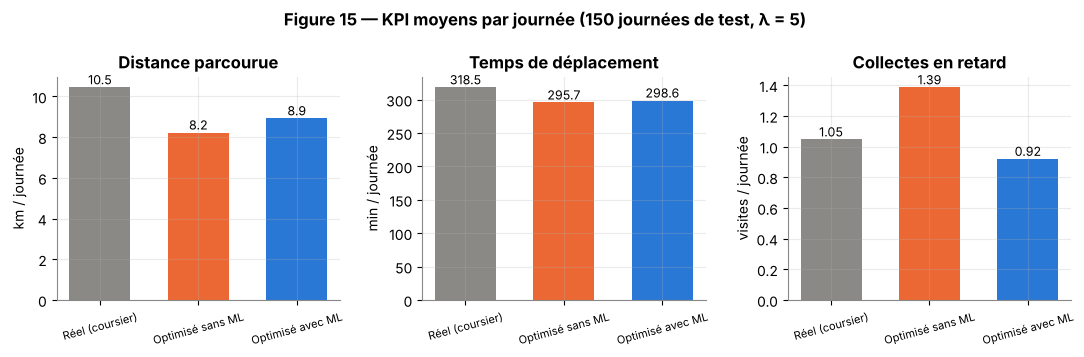

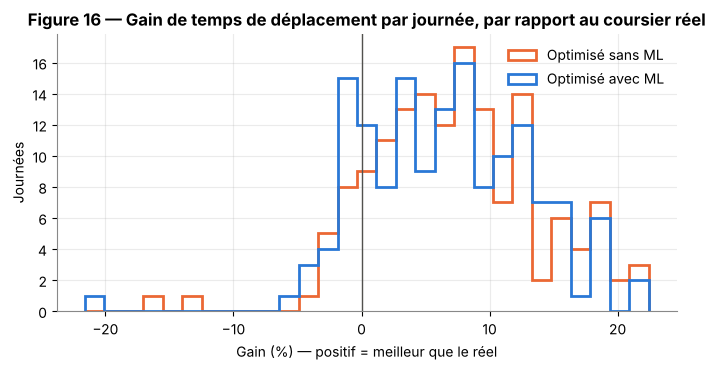

In [ ]:
# F.8 — Comparaison des KPI (figure principale)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (col, titre, unite) in zip(axes, [("distance_km", "Distance parcourue", "km / journée"),
                                         ("deplacement_min", "Temps de déplacement", "min / journée"),
                                         ("n_retard", "Collectes en retard", "visites / journée")]):
    vals = kpi[col].values
    ax.bar(list(NOMS.values()), vals, color=[C_REEL, C_SANS, C_AVEC], width=0.62)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.2f}" if col == "n_retard" else f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(titre); ax.set_ylabel(unite); ax.tick_params(axis="x", labelrotation=15, labelsize=8)
fig.suptitle(f"Figure 15 — KPI moyens par journée ({len(instances)} journées de test, λ = {LAMBDA:g})", fontweight="bold")
fig.tight_layout(); sauver(fig, "fig15_kpi_avant_apres"); plt.show()

# Distribution des gains par journée
gain_j = 100 * (piv["deplacement_min"].reel - piv["deplacement_min"].avec_ml) / piv["deplacement_min"].reel
gain_s = 100 * (piv["deplacement_min"].reel - piv["deplacement_min"].sans_ml) / piv["deplacement_min"].reel
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(min(gain_j.min(), gain_s.min()), max(gain_j.max(), gain_s.max()), 30)
ax.hist(gain_s, bins=bins, color=C_SANS, histtype="step", lw=2, label="Optimisé sans ML")
ax.hist(gain_j, bins=bins, color=C_AVEC, histtype="step", lw=2, label="Optimisé avec ML")
ax.axvline(0, color=C_GRIS, lw=1)
ax.set(title="Figure 16 — Gain de temps de déplacement par journée, par rapport au coursier réel",
       xlabel="Gain (%) — positif = meilleur que le réel", ylabel="Journées"); ax.legend()
sauver(fig, "fig16_gains_par_journee"); plt.show()
print(f"Gain médian par journée : sans ML {gain_s.median():.1f} % ; avec ML {gain_j.median():.1f} %")

**Lecture des résultats (λ = 5, 150 journées de test) :**
1. **L'optimisation apporte un gain net par rapport au coursier réel**, avec ou sans ML : environ **15 à 21 % de distance en moins** et **6 à 7 % de temps de déplacement en moins**. Dans plus de 80 % des journées, la tournée optimisée avec ML est plus courte en temps que la tournée réelle (test de Wilcoxon : p < 0,001).
2. **Sans ML, ce gain se paie en retards** : en simulation, l'optimiseur sans ML a *plus* de collectes en retard que l'ordre réel rejoué dans les mêmes conditions. Sa formule sous-estime les temps : sur les **vrais** trajets du jeu de test, son biais est d'environ −5 min par trajet (partie E) : il croit pouvoir faire un détour et arriver à l'heure, puis arrive en retard.
3. **Avec ML, l'optimiseur garde l'essentiel du gain et réduit les retards** : environ un tiers de retards en moins que sans ML, et moins que l'ordre réel rejoué en simulation. En contrepartie, il parcourt un peu plus de distance que l'optimiseur sans ML (environ +8 %) pour un temps de déplacement presque identique (environ +1 %).

**Conclusion intermédiaire :** dans ce dataset, la valeur ajoutée du ML n'est **pas** de raccourcir encore les tournées ; elle est de **rendre le plan fiable**, c'est-à-dire de respecter les échéances tout en gardant le gain de l'optimisation. C'est un **compromis** mesuré, et non un gain gratuit.

### F.9 Exemple concret d'une décision
Prenons une journée simulée et regardons les tournées sur la carte : le tracé gris est l'ordre réel, le tracé bleu est l'ordre décidé avec le ML.

Décision n°1 : le coursier vient de terminer la visite 1.
  - Réel     : il est allé à la visite 2 (distance 0.89 km)
  - Avec ML  : l'optimiseur choisit la visite 15 (distance 0.23 km)


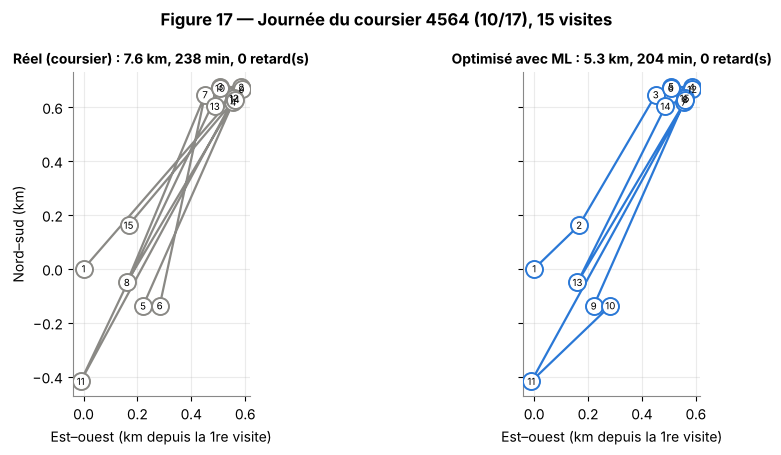

In [ ]:
# F.9 — Exemple de tournée avant / après

ecarts_j = piv["distance_km"].reel - piv["distance_km"].avec_ml
k_ex = int(ecarts_j.sort_values().index[int(len(ecarts_j) * 0.75)])     # une journée « typique haute », pas la meilleure
inst = instances[k_ex]; v = inst["v"]
# coordonnées locales en km (plus lisibles que des degrés)
xk = (v.lng.values - v.lng.values[0]) * 111.32 * np.cos(np.radians(v.lat.values[0]))
yk = (v.lat.values - v.lat.values[0]) * 110.57
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, s, coul in zip(axes, ["reel", "avec_ml"], [C_REEL, C_AVEC]):
    o = inst["resultats"][s]["ordre"]
    ax.plot(xk[o], yk[o], "-", color=coul, lw=1.6, zorder=2)
    ax.scatter(xk, yk, s=150, color="white", edgecolor=coul, lw=1.4, zorder=3)
    for rang, j in enumerate(o):
        ax.text(xk[j], yk[j], str(rang + 1), fontsize=7, ha="center", va="center", zorder=4)
    r = inst["resultats"][s]
    ax.set_title(f"{NOMS[s]} : {r['distance_km']:.1f} km, {r['deplacement_min']:.0f} min, {r['n_retard']} retard(s)", fontsize=10)
    ax.set_xlabel("Est–ouest (km depuis la 1re visite)"); ax.set_aspect("equal")
axes[0].set_ylabel("Nord–sud (km)")
fig.suptitle(f"Figure 17 — Journée du coursier {inst['courier_id']} ({str(inst['ds']).zfill(4)[:2]}/{str(inst['ds']).zfill(4)[2:]}), {inst['n']} visites",
             fontweight="bold")
fig.tight_layout(); sauver(fig, "fig17_exemple_tournee"); plt.show()

# Une décision isolée : le premier arrêt où les deux ordres divergent
o_r, o_m = inst["resultats"]["reel"]["ordre"], inst["resultats"]["avec_ml"]["ordre"]
pos = next((i for i in range(len(o_r)) if o_r[i] != o_m[i]), None)
if pos is not None:
    a = o_m[pos - 1]
    print(f"Décision n°{pos} : le coursier vient de terminer la visite {a + 1}.")
    print(f"  - Réel     : il est allé à la visite {o_r[pos] + 1} (distance {inst['dist'][a][o_r[pos]]:.2f} km)")
    print(f"  - Avec ML  : l'optimiseur choisit la visite {o_m[pos] + 1} (distance {inst['dist'][a][o_m[pos]]:.2f} km)")
    exemple_decision = {"rang": pos, "depuis": a + 1, "reel": o_r[pos] + 1, "ml": o_m[pos] + 1,
                        "dist_reel": inst["dist"][a][o_r[pos]], "dist_ml": inst["dist"][a][o_m[pos]]}

### F.10 Analyse de sensibilité : le compromis temps / retards (λ)
λ fixe l'importance donnée aux retards. On relance la simulation pour plusieurs valeurs de λ sur 50 journées.

,lambda,strategie,deplacement_min,n_retard,retard_min
0,0.0,sans_ml,265.781,1.40,99.407
1,0.0,avec_ml,266.704,1.68,91.921
2,1.0,sans_ml,267.725,1.02,19.777
3,1.0,avec_ml,270.576,0.78,27.540
4,5.0,sans_ml,269.899,0.98,20.872
5,5.0,avec_ml,271.194,0.64,18.133
6,20.0,sans_ml,269.761,0.98,20.656
7,20.0,avec_ml,271.511,0.66,18.059


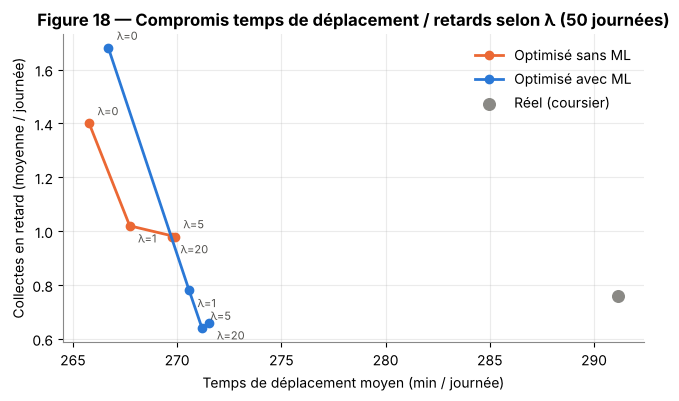

In [ ]:
# F.10 — Sensibilité à λ

LAMBDAS = [0.0, 1.0, 5.0, 20.0]
sens = []
for lam in LAMBDAS:
    for s in ("sans_ml", "avec_ml"):
        rs = [simuler(inst, s, lam=lam) for inst in instances[:50]]
        sens.append({"lambda": lam, "strategie": s, "deplacement_min": np.mean([r["deplacement_min"] for r in rs]),
                     "n_retard": np.mean([r["n_retard"] for r in rs]), "retard_min": np.mean([r["retard_min"] for r in rs])})
reel50 = sim[(sim.strategie == "reel") & (sim.journee < 50)][["deplacement_min", "n_retard"]].mean()
sens = pd.DataFrame(sens)
display(sens.round(3))
fig, ax = plt.subplots(figsize=(7.5, 4))
for s, coul in (("sans_ml", C_SANS), ("avec_ml", C_AVEC)):
    d = sens[sens.strategie == s]
    ax.plot(d.deplacement_min, d.n_retard, "o-", color=coul, lw=2, label=NOMS[s])
    for i, (_, r) in enumerate(d.iterrows()):
        ax.annotate(f"λ={r['lambda']:g}", (r.deplacement_min, r.n_retard), textcoords="offset points",
                    xytext=(6, 6) if i % 2 == 0 else (6, -12), fontsize=8, color=C_GRIS)
ax.scatter([reel50.deplacement_min], [reel50.n_retard], color=C_REEL, s=70, zorder=3, label="Réel (coursier)")
ax.set(title="Figure 18 — Compromis temps de déplacement / retards selon λ (50 journées)",
       xlabel="Temps de déplacement moyen (min / journée)", ylabel="Collectes en retard (moyenne / journée)"); ax.legend()
sauver(fig, "fig18_sensibilite_lambda"); plt.show()

**Lecture :**
* Avec **λ = 0** (retards ignorés), le ML n'apporte aucun avantage (il fait même un peu moins bien) : les deux optimiseurs ne cherchent qu'à raccourcir la tournée.
* Dès que les retards comptent (**λ ≥ 1**), l'optimiseur **avec ML** a systématiquement moins de retards que l'optimiseur **sans ML**.
* Surtout, **augmenter λ ne suffit pas à corriger l'optimiseur sans ML** : ses retards plafonnent, car le problème vient de ses **estimations de temps**, pas de la pénalité. Une bonne pénalité ne compense pas une mauvaise prédiction : c'est exactement le rôle du ML dans ce projet.

### F.11 Qualité de l'heuristique : comparaison avec l'optimum exact (MILP)
On résout le modèle F.1 **exactement** avec HiGHS sur des sous-problèmes de 8 visites (matrice ML de l'heure de départ) et on compare au résultat de l'heuristique.

In [ ]:
# F.11 — MILP exact (HiGHS) vs heuristique

def milp_tsptw(T, ech, tau, lam, limite_s=60):
    """T : matrice (n+1)x(n+1), nœud 0 = position de départ. Renvoie (coût optimal, ordre, temps de calcul)."""
    n = T.shape[0] - 1
    fin = n + 1                                              # nœud fictif de fin
    arcs = [(i, j) for i in range(n + 1) for j in range(1, n + 2) if i != j and not (i == 0 and j == fin)]
    na = len(arcs); ia = {a: k for k, a in enumerate(arcs)}
    nv = na + n + n                                          # x_arcs, a_1..a_n, L_1..L_n
    A_ = lambda j: na + (j - 1); L_ = lambda j: na + n + (j - 1)
    c = np.zeros(nv)
    for (i, j), k in ia.items():
        c[k] = T[i, j] if j != fin else 0.0
    c[na + n:] = lam
    rows, lo, hi = [], [], []
    def ajout(coefs, l, h):
        r = np.zeros(nv)
        for k, v in coefs: r[k] += v
        rows.append(r); lo.append(l); hi.append(h)
    for j in range(1, n + 2):                                # une entrée par nœud (et vers la fin)
        ajout([(ia[(i, j)], 1) for i in range(n + 1) if (i, j) in ia], 1, 1)
    for i in range(n + 1):                                   # une sortie par nœud
        ajout([(ia[(i, j)], 1) for j in range(1, n + 2) if (i, j) in ia], 1, 1)
    Mbig = tau + T.sum() + 1000
    for (i, j), k in ia.items():                             # propagation du temps
        if j == fin:
            continue
        if i == 0:   # a_j >= tau + T0j - M(1-x)  ->  a_j - M x >= tau + T0j - M
            ajout([(A_(j), 1), (k, -Mbig)], tau + T[0, j] - Mbig, np.inf)
        else:        # a_j - a_i - M x >= T_ij - M
            ajout([(A_(j), 1), (A_(i), -1), (k, -Mbig)], T[i, j] - Mbig, np.inf)
    for j in range(1, n + 1):                                # L_j >= a_j - l_j
        ajout([(L_(j), 1), (A_(j), -1)], -ech[j], np.inf)
    integ = np.zeros(nv); integ[:na] = 1
    lb = np.zeros(nv); ub = np.full(nv, np.inf); ub[:na] = 1
    t0 = time.time()
    res = milp(c, constraints=LinearConstraint(np.array(rows), lo, hi), integrality=integ,
               bounds=Bounds(lb, ub), options={"time_limit": limite_s})
    duree = time.time() - t0
    x = res.x[:na] > 0.5
    succ = {i: j for (i, j), k in ia.items() if x[k]}
    ordre, cur = [], 0
    while succ[cur] != fin:
        cur = succ[cur]; ordre.append(cur)
    return res.fun, ordre, duree

comparaison_milp = []
for inst in instances[:30]:
    noeuds = list(range(9))                                  # départ + 8 visites
    h = idx_heure(inst["fin"][0])
    T = np.array(inst["M_ml"][h])[np.ix_(noeuds, noeuds)]
    ech = np.array(inst["echeance"])[noeuds]                 # échéances réelles de ces visites
    tau = float(inst["fin"][0])                              # même heure de départ que la réalité
    opt, ordre_opt, duree = milp_tsptw(T, ech, tau, LAMBDA)
    Mfix = [T.tolist()] * len(HEURES)                         # même matrice à toute heure (comparaison équitable)
    t1 = time.time(); route, ch = planifier(0, tau, list(range(1, 9)), Mfix, ech, LAMBDA); dh = time.time() - t1
    comparaison_milp.append({"journee": inst["ds"], "cout_milp": opt, "cout_heuristique": ch,
                             "ecart_pct": 100 * (ch - opt) / opt, "temps_milp_s": duree, "temps_heuristique_s": dh})
cmp_milp = pd.DataFrame(comparaison_milp)
display(cmp_milp.describe().loc[["mean", "50%", "max"]].round(4))
print(f"L'heuristique trouve l'optimum prouvé dans {(cmp_milp.ecart_pct < 1e-6).mean():.0%} des 30 instances.")

L'heuristique trouve l'optimum prouvé dans 83% des 30 instances.


,journee,cout_milp,cout_heuristique,ecart_pct,temps_milp_s,temps_heuristique_s
mean,905.4667,88.495,88.6317,0.1660,0.4001,0.0010
50%,906.0000,83.685,83.6850,0.0000,0.2138,0.0009
max,912.0000,128.120,128.1200,3.1636,2.2594,0.0058


**Pourquoi ne pas utiliser le MILP partout ?** Le temps de calcul exact explose avec le nombre de visites (problème NP-difficile), alors qu'il faut une réponse instantanée à chaque arrêt. Le MILP sert de **certificat de qualité** : il prouve que l'heuristique est très proche de l'optimum sur des instances où l'optimum est calculable.

### F.12 Scénario optimiste : si toutes les tâches étaient connues dès le matin
À titre de **borne** (non réaliste), on relance avec toutes les tâches connues au départ. Cela mesure ce que l'on perd à cause de l'arrivée progressive des commandes.

In [ ]:
# F.12 — Borne « information parfaite »

borne = []
for inst in instances[:50]:
    r = simuler(inst, "avec_ml", toutes_connues=True)
    borne.append({"deplacement_min": r["deplacement_min"], "distance_km": r["distance_km"], "n_retard": r["n_retard"]})
borne = pd.DataFrame(borne).mean()
ref50 = sim[sim.journee < 50].groupby("strategie")[["deplacement_min", "distance_km", "n_retard"]].mean()
display(pd.concat([ref50.rename(index=NOMS), borne.rename("Avec ML — tâches connues au départ (borne)").to_frame().T]).round(2))

,deplacement_min,distance_km,n_retard
Optimisé avec ML,271.19,8.73,0.64
Réel (coursier),291.13,10.12,0.76
Optimisé sans ML,269.90,8.22,0.98
Avec ML — tâches connues au départ (borne),248.27,6.66,0.82


## G. Exports pour le rapport et la plateforme web

In [ ]:

# G — Exports JSON / CSV
def to_py(o):
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(type(o))

resultats_optim = {
    "lambda": LAMBDA, "n_journees": len(instances), "heures_matrices": [int(h) for h in HEURES],
    "kpi_moyens": kpi.rename(index=NOMS).round(4).reset_index(names="strategie").to_dict(orient="records"),
    "kpi_totaux": kpi_tot.rename(index=NOMS).round(3).reset_index(names="strategie").to_dict(orient="records"),
    "gains": gains,
    "gain_median_deplacement_pct": {"sans_ml": float(gain_s.median()), "avec_ml": float(gain_j.median())},
    "gains_par_journee_pct": {"sans_ml": gain_s.round(3).tolist(), "avec_ml": gain_j.round(3).tolist()},
    "validation_evaluateur": {"ratio_duree": ratio, "correlation": corr_duree, "erreur_relative_mediane": err_duree},
    "sensibilite_lambda": sens.round(4).to_dict(orient="records"),
    "reel_50": reel50.round(4).to_dict(),
    "milp_vs_heuristique": {"ecart_moyen_pct": float(cmp_milp.ecart_pct.mean()), "ecart_max_pct": float(cmp_milp.ecart_pct.max()),
                            "part_optimum": float((cmp_milp.ecart_pct < 1e-6).mean()),
                            "temps_milp_moyen_s": float(cmp_milp.temps_milp_s.mean()),
                            "temps_heuristique_moyen_s": float(cmp_milp.temps_heuristique_s.mean()), "n_instances": len(cmp_milp)},
    "borne_information_parfaite": borne.round(4).to_dict(),
    "retards_observes_moyens": float(np.mean(retards_obs)),
    "exemple_decision": exemple_decision,
    "exemple": {"journee": k_ex, "courier_id": instances[k_ex]["courier_id"], "ds": instances[k_ex]["ds"]},
    "par_journee": sim.round(3).to_dict(orient="records"),
}
(EXP_DIR / "resultats_ml.json").write_text(json.dumps(resultats_ml, default=to_py, ensure_ascii=False, indent=1), encoding="utf-8")
(EXP_DIR / "resultats_optimisation.json").write_text(json.dumps(resultats_optim, default=to_py, ensure_ascii=False, indent=1), encoding="utf-8")
(EXP_DIR / "donnees_dashboard.json").write_text(json.dumps(eda, default=to_py, ensure_ascii=False), encoding="utf-8")
sim.to_csv(EXP_DIR / "resultats_par_journee.csv", index=False)
tableau_ml.round(4).to_csv(EXP_DIR / "comparaison_modeles.csv")

# --- Scénarios pour le simulateur web : 24 journées (≤ 20 visites), mêmes matrices que la simulation ---
web_sc = []
for k, inst in enumerate(instances):
    if inst["n"] > 20 or len(web_sc) >= 24:
        continue
    v = inst["v"]
    r1 = lambda M: M
    web_sc.append({"id": k, "courier_id": inst["courier_id"], "ds": inst["ds"], "n": inst["n"],
                   "lng": v.lng.round(5).tolist(), "lat": v.lat.round(5).tolist(), "n_colis": v.n_colis.tolist(),
                   "aoi_type": v.aoi_type.tolist(),
                   "connue": np.round(inst["connue"], 1).tolist(), "echeance": np.round(inst["echeance"], 1).tolist(),
                   "debut": np.round(inst["debut"], 1).tolist(), "fin": np.round(inst["fin"], 1).tolist(),
                   "dist": inst["dist"], "resultats_notebook": {s: {c: r[c] for c in r if c != "ordre"} for s, r in inst["resultats"].items()},
                   "M_sans": r1(inst["M_sans"]), "M_ml": r1(inst["M_ml"]), "M_eval": r1(inst["M_eval"])})
(WEB_DIR / "scenarios.json").write_text(json.dumps({"heure_min": H0, "heure_max": H1, "lambda_defaut": LAMBDA,
                                                    "scenarios": web_sc}, default=to_py))
# Échantillon de 2 000 colis pour l'explorateur de données
raw.sample(2000, random_state=SEED).sort_values(["courier_id", "ds"]).to_csv(WEB_DIR / "echantillon_colis.csv", index=False)
for f in ("resultats_ml.json", "resultats_optimisation.json", "donnees_dashboard.json"):
    (WEB_DIR / f).write_text((EXP_DIR / f).read_text(encoding="utf-8"), encoding="utf-8")
# Fichier unique chargé par le site (fonctionne aussi en ouvrant index.html par double-clic)
ech_web = raw.sample(2000, random_state=SEED).sort_values(["courier_id", "ds"])
paquet = {"ml": resultats_ml, "optim": {k: v for k, v in resultats_optim.items() if k != "par_journee"},
          "eda": eda, "scenarios": json.loads((WEB_DIR / "scenarios.json").read_text()),
          "echantillon": {"colonnes": list(ech_web.columns), "lignes": ech_web.astype(object).where(ech_web.notna(), None).values.tolist()}}
(WEB_DIR / "donnees.js").write_text("window.PROJET = " + json.dumps(paquet, default=to_py, ensure_ascii=False) + ";", encoding="utf-8")
print("Exports terminés :", sorted(p.name for p in EXP_DIR.iterdir()), "|", len(web_sc), "scénarios web")

Exports terminés : ['comparaison_modeles.csv', 'donnees_dashboard.json', 'resultats_ml.json', 'resultats_optimisation.json', 'resultats_par_journee.csv'] | 24 scénarios web


## H. Conclusion

*Les chiffres ci-dessous sont recalculés à partir des résultats ci-dessus (ils ne sont pas saisis à la main).*

In [ ]:
# H — Synthèse chiffrée automatique

k_r, k_s, k_m = kpi.loc["reel"], kpi.loc["sans_ml"], kpi.loc["avec_ml"]
b = tableau_ml.loc["Baseline (moyennes historiques)"]; f = tableau_ml.loc[NOM_FINAL]
print(f"""1. Problème : ordonner dynamiquement les collectes d'un coursier, avec des échéances.
2. EDA : fenêtres de {duree_fen.median():.0f} min ; {eda['indicateurs']['taux_retard_reel']:.2%} de retards réels ;
   seulement {eda['indicateurs']['part_connue_avant_debut']:.0%} des visites connues avant la première collecte -> optimisation dynamique.
3. ML : {NOM_FINAL} — MAE {f.MAE:.2f} min contre {b.MAE:.2f} min pour la formule historique ({100*(f.MAE-b.MAE)/b.MAE:+.1f} %), R² {f.R2:.2f}.
4. Optimisation ({len(instances)} journées de test, λ = {LAMBDA:g}) :
   distance       : réel {k_r.distance_km:.2f} km | sans ML {k_s.distance_km:.2f} | avec ML {k_m.distance_km:.2f} km/journée
   déplacement    : réel {k_r.deplacement_min:.1f} min | sans ML {k_s.deplacement_min:.1f} | avec ML {k_m.deplacement_min:.1f} min/journée
   retards        : réel {k_r.n_retard:.2f} | sans ML {k_s.n_retard:.2f} | avec ML {k_m.n_retard:.2f} visites/journée
5. Valeur de l'optimisation (avec ML vs réel) : distance {gains['distance_avec_vs_reel_pct']:+.1f} %, temps de déplacement {gains['deplacement_avec_vs_reel_pct']:+.1f} %.
6. Valeur ajoutée du ML (avec vs sans ML) : temps {gains['deplacement_avec_vs_sans_pct']:+.1f} % (p = {gains['p_wilcoxon_deplacement_avec_vs_sans']:.2g}),
   distance {gains['distance_avec_vs_sans_pct']:+.1f} % (p = {gains['p_wilcoxon_distance_avec_vs_sans']:.2g}).
7. Heuristique : écart moyen de {cmp_milp.ecart_pct.mean():.2f} % à l'optimum MILP sur 30 instances de 8 visites.""")

1. Problème : ordonner dynamiquement les collectes d'un coursier, avec des échéances.
2. EDA : fenêtres de 120 min ; 0.47% de retards réels ;
   seulement 46% des visites connues avant la première collecte -> optimisation dynamique.
3. ML : Gradient Boosting — MAE 9.01 min contre 7.98 min pour la formule historique (+13.0 %), R² 0.11.
4. Optimisation (150 journées de test, λ = 5) :
   distance       : réel 10.45 km | sans ML 8.23 | avec ML 8.93 km/journée
   déplacement    : réel 318.5 min | sans ML 295.7 | avec ML 298.6 min/journée
   retards        : réel 1.05 | sans ML 1.39 | avec ML 0.92 visites/journée
5. Valeur de l'optimisation (avec ML vs réel) : distance -14.6 %, temps de déplacement -6.2 %.
6. Valeur ajoutée du ML (avec vs sans ML) : temps +1.0 % (p = 0.00024),
   distance +8.5 % (p = 2.5e-13).
7. Heuristique : écart moyen de 0.17 % à l'optimum MILP sur 30 instances de 8 visites.


### Synthèse
* **Problème initial :** ordonner, à chaque arrêt, les collectes d'un coursier dont les tâches arrivent au fil de la journée, sous des échéances de 2 h.
* **EDA :** les coursiers respectent déjà très bien les échéances ; moins de la moitié des tâches sont connues le matin, d'où une **optimisation dynamique** ; le temps dépend de la distance mais aussi de l'heure, du lieu et d'éléments non observés.
* **ML :** le Gradient Boosting prédit des temps **non biaisés**, contrairement à la formule historique qui les sous-estime ; sa précision reste limitée (R² ≈ 0,1).
* **Décisions optimisées :** un MILP de type TSPTW, résolu à chaque arrêt par une heuristique 2-opt/or-opt validée contre l'optimum exact (HiGHS).
* **Gains simulés :** l'optimisation raccourcit les tournées par rapport au terrain ; le ML permet de conserver ce gain **sans dégrader** le respect des échéances.

### Limites
* **Les gains de temps sont simulés**, pas observés : une tournée qui n'a jamais été faite ne peut être évaluée qu'avec un modèle. Nous l'avons atténué avec un évaluateur **indépendant** (autres coursiers) validé sur les tournées réelles (Figure 14). La **distance**, elle, est calculée exactement.
* Les coursiers réels savent des choses absentes des données (portail fermé, client absent, appel téléphonique, livraisons à faire en parallèle) : une partie de « l'écart » au réel n'est pas récupérable en pratique.
* La distance est à vol d'oiseau : le réseau routier (fourni dans LaDe, `roads.csv`) donnerait des distances plus fidèles.
* L'année est inconnue : le jour de la semaine n'a pas pu être utilisé.

### Pistes d'amélioration
* Distances routières à partir de `roads.csv`.
* Version multi-coursiers (VRPTW) : réaffecter des visites entre coursiers voisins.
* Prédire l'**arrivée des futures tâches** pour anticiper les détours.
* Modèle de temps avec intervalles de confiance (régression quantile) pour des tournées robustes.